# Hydro, Solar, Biomass and Geothermal Energy in the Midwestern U.S. Region
## Review 2: Forecasting (separate models for each resource)

**Research question:** How do hydro, solar, biomass and geothermal electricity generation vary over time in the Midwestern U.S. region, and
what specific trends, seasonal cycles and temporal dependencies can be isolated to accurately forecast their future contributions?

A **separate set of models is built for each resource** (hydro, solar, biomass), because Review 1 showed that each has its own trend,
seasonality and stationarity behaviour. Geothermal generation is zero in every month in the Midwest, so no model is needed (section 10).

| Step | Models |
|---|---|
| Baseline | Naive, Seasonal Naive |
| Classical | ARIMA (with differencing), SARIMA, SARIMAX |
| Exponential smoothing | SES, Holt, Holt-Winters additive / multiplicative |
| Machine learning | Linear Regression, Random Forest |
| Neural network | Multi-layer perceptron (scikit-learn `MLPRegressor`) |

## 1. Setup and data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import itertools
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing, Holt
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

In [17]:
DATA_PATH = "usa_state_renewable_monthly_2001_2026.csv"

df = pd.read_csv(DATA_PATH)
df["month"] = pd.to_datetime(df["month"])

region_df = df[df["census_region"] == "Midwest"].copy()

region = (
    region_df
    .groupby("month")[["hydro", "solar", "biomass", "wind"]]
    .sum()
    .asfreq("MS")
)

RESOURCES = ["hydro", "solar", "biomass", "wind"]         
SOLAR_START = "2012-01-01"                     

series = {
    "hydro":   region["hydro"],
    "solar":   region["solar"].loc[SOLAR_START:],
    "biomass": region["biomass"],
    "wind" : region["wind"]
}
for r in RESOURCES:
    print(f"{r:8s}: {series[r].index.min():%b %Y} - {series[r].index.max():%b %Y}, {len(series[r])} months")

hydro   : Jan 2001 - Jul 2026, 307 months
solar   : Jan 2012 - Jul 2026, 175 months
biomass : Jan 2001 - Jul 2026, 307 months
wind    : Jan 2001 - Jul 2026, 307 months


## 2. Train / Test Split

* The split is **chronological**: the model only ever sees the past. Shuffling is not used, because it would let the model learn from future months.
* **Test set = the last 24 months (Aug 2024 – Jul 2026)**. That is two full seasonal cycles, so each calendar month is tested twice.
* Training = everything before Aug 2024. That is 283 months for hydro and biomass and 151 months for solar.
* Every model forecasts all 24 test months **from the end of the training data** (multi-step forecasting). This is how the model would be used in practice.

In [3]:
TEST_MONTHS = 24
H_FUTURE = 12          # final forecast horizon after the evaluation

train, test = {}, {}
for r in RESOURCES:
    train[r] = series[r].iloc[:-TEST_MONTHS]
    test[r] = series[r].iloc[-TEST_MONTHS:]
    print(f"{r:8s}: train {train[r].index.min():%b %Y}-{train[r].index.max():%b %Y} ({len(train[r])}), "
          f"test {test[r].index.min():%b %Y}-{test[r].index.max():%b %Y} ({len(test[r])})")

hydro   : train Jan 2001-Jul 2024 (283), test Aug 2024-Jul 2026 (24)
solar   : train Jan 2012-Jul 2024 (151), test Aug 2024-Jul 2026 (24)
biomass : train Jan 2001-Jul 2024 (283), test Aug 2024-Jul 2026 (24)
wind    : train Jan 2001-Jul 2024 (283), test Aug 2024-Jul 2026 (24)


## 3. Accuracy metrics

* **MAE**: average absolute error (GWh).
* **RMSE**: like MAE, but penalises large errors more (GWh).
* **MAPE**: average absolute percentage error (%). It is scale-free, so the three resources can be compared.
* **MASE**: MAE divided by the in-sample error of the seasonal naive forecast. **MASE < 1** means better than a naive seasonal forecast on the training data.

In [4]:
def evaluate(actual, forecast, train_series):
    actual, forecast = np.asarray(actual, float), np.asarray(forecast, float)
    error = actual - forecast
    naive_scale = np.mean(np.abs(train_series.values[12:] - train_series.values[:-12]))
    return {
        "MAE": np.mean(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "MAPE": np.mean(np.abs(error / actual)) * 100,
        "MASE": np.mean(np.abs(error)) / naive_scale,
    }

## 4. Model functions

Every model is a function `model(train_series, h)` that returns `h` future values. That way the **same** functions are applied
to each resource, and the best model can be re-fitted on all the data for the final forecast.

**Transformation.** As in Review 1, a resource whose seasonal swings grow with its level (correlation between the 12-month rolling mean
and rolling std > 0.7) is modelled on the **log scale** by the ARIMA, SARIMA, SARIMAX and ML models, and converted back with `exp()`.
The other resources are modelled on their original scale.

In [5]:
USE_LOG = {r: bool(train[r].rolling(12).mean().corr(train[r].rolling(12).std()) > 0.7) for r in RESOURCES}
print("Log scale used for:", USE_LOG)

def to_model_scale(y, r):
    return np.log(y) if USE_LOG[r] else y

def from_model_scale(z, r):
    return np.exp(z) if USE_LOG[r] else z

# ---------------- Baselines ----------------
def naive_forecast(y, h, r=None):
    """Every future month = the last observed month."""
    return np.repeat(y.iloc[-1], h)

def seasonal_naive_forecast(y, h, r=None):
    """Every future month = the same month one year earlier."""
    last_year = y.iloc[-12:].values
    return np.array([last_year[i % 12] for i in range(h)])

Log scale used for: {'hydro': True, 'solar': True, 'biomass': False, 'wind': True}


### Choosing the differencing orders (d, D) from the training data
The rule is the same as in Review 1. Use a seasonal difference (D = 1) when seasonal strength > 0.64. Then add a first difference (d = 1) if ADF and KPSS still disagree with stationarity.

In [6]:
from statsmodels.tsa.seasonal import seasonal_decompose

def choose_differencing(z):
    d_parts = seasonal_decompose(z, model="additive", period=12)
    resid, seas = d_parts.resid.dropna(), d_parts.seasonal[d_parts.resid.notna()]
    seasonal_strength = max(0, 1 - resid.var() / (seas + resid).var())
    D = 1 if seasonal_strength > 0.64 else 0
    x = z.diff(12).dropna() if D else z
    adf_p = adfuller(x)[1]
    kpss_p = kpss(x, regression="c", nlags="auto")[1]
    d = 0 if (adf_p < 0.05 and kpss_p > 0.05) else 1
    return d, D, seasonal_strength, adf_p, kpss_p

diff_orders = {}
rows = []
for r in RESOURCES:
    d, D, fs, adf_p, kpss_p = choose_differencing(to_model_scale(train[r], r))
    diff_orders[r] = (d, D)
    rows.append({"resource": r, "seasonal_strength": fs, "D": D, "ADF p (after D)": adf_p,
                 "KPSS p (after D)": kpss_p, "d": d})
pd.DataFrame(rows).set_index("resource")

,seasonal_strength,D,ADF p (after D),KPSS p (after D),d
resource,,,,,
hydro,0.378,0,0.279,0.010,1
solar,0.790,1,0.003,0.100,0
biomass,0.444,0,0.659,0.010,1
wind,0.827,1,0.093,0.010,1


### ARIMA / SARIMA / SARIMAX order selection (AIC grid search on the training data)

In [7]:
def trend_term(d, D):
    return ["n", "t"] if d + D == 1 else (["n", "c"] if d + D == 0 else ["n"])

def grid_search(z, d, D, seasonal, exog=None):
    results = []
    pq = range(0, 3) if seasonal else range(0, 4)
    PQ = range(0, 2) if seasonal else [0]
    for p, q, P, Q in itertools.product(pq, pq, PQ, PQ):
        for t in trend_term(d, D if seasonal else 0):
            seasonal_order = (P, D, Q, 12) if seasonal else (0, 0, 0, 0)
            try:
                fit = ARIMA(z, exog=exog, order=(p, d, q), seasonal_order=seasonal_order, trend=t).fit()
                resid = fit.resid.iloc[d + 12 * seasonal_order[1] + 1:]
                # reject failed / degenerate fits: the residuals of a sensible model are centred near 0
                # and smaller than the series itself (a broken fit can report a meaninglessly low AIC)
                if not np.isfinite(fit.aic) or abs(resid.mean()) > 0.5 * z.std() or resid.std() > z.std():
                    continue
                results.append({"order": (p, d, q), "seasonal_order": seasonal_order, "trend": t, "AIC": fit.aic})
            except Exception:
                pass
    return pd.DataFrame(results).sort_values("AIC").reset_index(drop=True)

# SARIMAX exogenous variables: Fourier terms (sin/cos of the month) and a time index.
# They are known in advance for any future month, so there is NO data leakage.
# (Hydro, solar, biomass of the same month cannot be used to predict each other: they are not known in the future.)
def fourier_exog(index, start, with_time=True):
    t = ((index.year - start.year) * 12 + (index.month - start.month)).values + 1
    month = index.month.values
    X = pd.DataFrame({
        "sin1": np.sin(2 * np.pi * month / 12), "cos1": np.cos(2 * np.pi * month / 12),
        "sin2": np.sin(4 * np.pi * month / 12), "cos2": np.cos(4 * np.pi * month / 12),
    }, index=index)
    if with_time:          # a time index is only added when the series is NOT differenced (differencing removes it)
        X.insert(0, "time", t)
    return X

In [8]:
orders = {}
for r in RESOURCES:
    z = to_model_scale(train[r], r)
    d, D = diff_orders[r]
    # non-seasonal differencing order for ARIMA / SARIMAX: d=1 unless the series itself is already stationary
    d_ns = 0 if (adfuller(z)[1] < 0.05 and kpss(z, regression="c", nlags="auto")[1] > 0.05) else 1
    arima_grid = grid_search(z, d_ns, 0, seasonal=False)
    sarima_grid = grid_search(z, d, D, seasonal=True)
    X = fourier_exog(z.index, z.index[0], with_time=(d_ns == 0))
    sarimax_grid = grid_search(z, d_ns, 0, seasonal=False, exog=X)                # ARIMA errors + Fourier (+ time) regressors
    orders[r] = {"ARIMA": arima_grid.iloc[0].to_dict(), "SARIMA": sarima_grid.iloc[0].to_dict(),
                 "SARIMAX": sarimax_grid.iloc[0].to_dict()}
    print(f"===== {r.upper()} =====")
    print("Top 3 SARIMA models by AIC:")
    print(sarima_grid.head(3).to_string(index=False))
    for k, v in orders[r].items():
        print(f"  selected {k:8s}: order={v['order']}, seasonal={v['seasonal_order']}, trend={v['trend']}, AIC={v['AIC']:.1f}")
    print()

===== HYDRO =====
Top 3 SARIMA models by AIC:
    order seasonal_order trend      AIC
(1, 1, 1)  (1, 0, 1, 12)     n -301.207
(1, 1, 2)  (1, 0, 1, 12)     n -299.518
(2, 1, 1)  (1, 0, 1, 12)     n -299.475
  selected ARIMA   : order=(2, 1, 3), seasonal=(0, 0, 0, 0), trend=n, AIC=-270.1
  selected SARIMA  : order=(1, 1, 1), seasonal=(1, 0, 1, 12), trend=n, AIC=-301.2
  selected SARIMAX : order=(1, 1, 1), seasonal=(0, 0, 0, 0), trend=n, AIC=-293.1

===== SOLAR =====
Top 3 SARIMA models by AIC:
    order seasonal_order trend     AIC
(1, 0, 0)  (1, 1, 1, 12)     t -45.731
(1, 0, 0)  (0, 1, 1, 12)     t -45.330
(1, 0, 1)  (0, 1, 1, 12)     t -44.100
  selected ARIMA   : order=(2, 1, 2), seasonal=(0, 0, 0, 0), trend=t, AIC=-18.4
  selected SARIMA  : order=(1, 0, 0), seasonal=(1, 1, 1, 12), trend=t, AIC=-45.7
  selected SARIMAX : order=(3, 1, 3), seasonal=(0, 0, 0, 0), trend=t, AIC=-53.9

===== BIOMASS =====
Top 3 SARIMA models by AIC:
    order seasonal_order trend      AIC
(1, 1, 1)  (1, 0,

In [9]:
def make_arima(kind):
    def model(y, h, r):
        o = orders[r][kind]
        z = to_model_scale(y, r)
        if kind == "SARIMAX":
            with_time = o["order"][1] == 0
            X = fourier_exog(z.index, series[r].index[0], with_time)
            future_index = pd.date_range(z.index[-1] + pd.offsets.MonthBegin(), periods=h, freq="MS")
            X_future = fourier_exog(future_index, series[r].index[0], with_time)
            fit = ARIMA(z, exog=X, order=o["order"], seasonal_order=o["seasonal_order"], trend=o["trend"]).fit()
            return from_model_scale(fit.forecast(h, exog=X_future).values, r)
        fit = ARIMA(z, order=o["order"], seasonal_order=o["seasonal_order"], trend=o["trend"]).fit()
        return from_model_scale(fit.forecast(h).values, r)
    return model

### Fourier Terms as Exogenous Variables

Fourier terms, represented by sine and cosine functions, are used as exogenous variables in the SARIMAX model to capture the recurring seasonal patterns in monthly renewable energy generation. Since solar, wind, and other renewable energy sources may exhibit annual variations due to seasonal weather conditions, these terms help the model represent periodic fluctuations in the data.
$$y_t = \beta_1 \sin(1_t) + \beta_2 \cos(1_t)$$

### Holt-Winters / exponential smoothing

In [10]:
def ses_forecast(y, h, r=None):
    return SimpleExpSmoothing(y, initialization_method="estimated").fit().forecast(h).values

def holt_forecast(y, h, r=None):
    return Holt(y, damped_trend=True, initialization_method="estimated").fit().forecast(h).values

def make_hw(seasonal, damped):
    def model(y, h, r=None):
        fit = ExponentialSmoothing(y, trend="add", damped_trend=damped, seasonal=seasonal,
                                   seasonal_periods=12, initialization_method="estimated").fit()
        return fit.forecast(h).values
    return model

# Exponential Smoothing Forecasting Methods

## 1. Simple Exponential Smoothing (SES)

Simple Exponential Smoothing forecasts future values using the estimated level of the time series, without explicitly modeling trend or seasonality.

**Level equation:**

$$
L_t = \alpha y_t + (1-\alpha)L_{t-1}
$$

**Forecast equation:**

$$
\hat{y}_{t+h} = L_t
$$

Where:

- $y_t$ is the actual observation at time $t$.
- $L_t$ is the estimated level at time $t$.
- $\alpha$ is the smoothing parameter, where $0 < \alpha < 1$.
- $h$ is the forecast horizon.

SES is suitable for series that fluctuate around a relatively stable level without a systematic trend or seasonal pattern.

## 2. Holt's Linear Method with Damped Trend

Holt's method extends SES by modeling both the level and trend. A damped trend reduces the influence of the estimated trend as the forecast horizon increases.

**Level equation:**

$$
L_t = \alpha y_t + (1-\alpha)(L_{t-1}+\phi T_{t-1})
$$

**Trend equation:**

$$
T_t = \beta(L_t-L_{t-1})+(1-\beta)\phi T_{t-1}
$$

**Forecast equation:**

$$
\hat{y}_{t+h} = L_t + \sum_{i=1}^{h}\phi^i T_t
$$

Where:

- $L_t$ is the estimated level.
- $T_t$ is the estimated trend.
- $\alpha$ is the level smoothing parameter.
- $\beta$ is the trend smoothing parameter.
- $\phi$ is the damping parameter, typically between 0 and 1.
- $h$ is the forecast horizon.

The damped trend is useful when a historical upward or downward trend is not expected to continue indefinitely at the same rate.

## 3. Holt–Winters Exponential Smoothing

Holt–Winters extends Holt's method by incorporating a seasonal component. In the implementation, the trend is additive, while seasonality can be additive or multiplicative.

### 3.1 Additive Seasonality

Additive seasonality is appropriate when seasonal fluctuations remain approximately constant in magnitude over time.

**Level equation:**

$$
L_t = \alpha(y_t-S_{t-m})+(1-\alpha)(L_{t-1}+\phi T_{t-1})
$$

**Trend equation:**

$$
T_t = \beta(L_t-L_{t-1})+(1-\beta)\phi T_{t-1}
$$

**Seasonal equation:**

$$
S_t = \gamma(y_t-L_t)+(1-\gamma)S_{t-m}
$$

**Forecast equation:**

$$
\hat{y}_{t+h}=L_t+\sum_{i=1}^{h}\phi^iT_t+S_{t-m+1+((h-1)\bmod m)}
$$

### 3.2 Multiplicative Seasonality

Multiplicative seasonality is appropriate when seasonal fluctuations change proportionally with the level of the series.

**Level equation:**

$$
L_t = \alpha\frac{y_t}{S_{t-m}}+(1-\alpha)(L_{t-1}+\phi T_{t-1})
$$

**Trend equation:**

$$
T_t = \beta(L_t-L_{t-1})+(1-\beta)\phi T_{t-1}
$$

**Seasonal equation:**

$$
S_t = \gamma\frac{y_t}{L_t}+(1-\gamma)S_{t-m}
$$

**Forecast equation:**

$$
\hat{y}_{t+h}=
\left(L_t+\sum_{i=1}^{h}\phi^iT_t\right)
S_{t-m+1+((h-1)\bmod m)}
$$

Where:

- $L_t$ is the estimated level.
- $T_t$ is the estimated trend.
- $S_t$ is the estimated seasonal component.
- $\alpha$, $\beta$, and $\gamma$ are smoothing parameters.
- $\phi$ is the trend damping parameter; when damping is disabled, $\phi=1$.
- $m$ is the seasonal period, set to 12 for monthly data with annual seasonality.
- $h$ is the forecast horizon.

## 4. Application to Renewable Energy Forecasting

These methods are used as baseline forecasting models for monthly renewable energy generation.

- **SES:** establishes a baseline using the level of generation.
- **Holt's method:** captures the level and trend while allowing the trend's influence to diminish over longer forecast horizons.
- **Holt–Winters:** captures the level, trend, and recurring annual seasonal patterns.


### Machine learning and neural network

**Features** are all built from past values only:
* lag_1, lag_2, lag_3, lag_6, lag_12;
* rolling_mean_3, rolling_mean_6, rolling_mean_12;
* month (as sin/cos), quarter.

**Target.** Tree models cannot predict values higher than anything they have seen, and solar keeps reaching new highs. The ML models therefore predict the
**change from the same month last year**, w(t) = z(t) − z(t−12), where z is the (log) series. The forecast is rebuilt as z(t) = z(t−12) + w(t).

**Forecasting.** Multi-step forecasts are made **recursively**: each prediction is fed back in as a lag for the next month.

In [11]:
LAGS = [1, 2, 3, 6, 12]

def make_features(w_history, month):
    row = {f"lag_{k}": w_history[-k] for k in LAGS}
    for win in (3, 6, 12):
        row[f"rolling_mean_{win}"] = np.mean(w_history[-win:])
    row["month_sin"] = np.sin(2 * np.pi * month / 12)
    row["month_cos"] = np.cos(2 * np.pi * month / 12)
    row["quarter"] = (month - 1) // 3 + 1
    return row

def build_training_table(y, r):
    z = to_model_scale(y, r)
    w = (z - z.shift(12)).dropna()
    rows, targets = [], []
    for i in range(12, len(w)):
        rows.append(make_features(list(w.values[:i]), w.index[i].month))
        targets.append(w.values[i])
    return pd.DataFrame(rows), np.array(targets)

def make_ml(estimator_factory):
    def model(y, h, r):
        X, target = build_training_table(y, r)
        est = estimator_factory().fit(X, target)
        z = list(to_model_scale(y, r).values)
        w = list((to_model_scale(y, r) - to_model_scale(y, r).shift(12)).dropna().values)
        month = y.index[-1].month
        out = []
        for _ in range(h):
            month = month % 12 + 1
            w_hat = est.predict(pd.DataFrame([make_features(w, month)]))[0]
            z_new = z[-12] + w_hat
            w.append(w_hat); z.append(z_new); out.append(z_new)
        return from_model_scale(np.array(out), r)
    return model

linear_model = make_ml(lambda: LinearRegression())
forest_model = make_ml(lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42))
mlp_model = make_ml(lambda: make_pipeline(StandardScaler(),
                                          MLPRegressor(hidden_layer_sizes=(16, 8), alpha=0.01, max_iter=3000,
                                                       early_stopping=True, random_state=42)))

**Why a small MLP and not an LSTM/GRU?** Each resource has only 151–283 training months, which gives about 130–260 training rows.
That is far too few for recurrent deep-learning models, which have thousands of parameters and would overfit.
A small feed-forward neural network (16 and 8 hidden units, L2 penalty, early stopping) is the most complex network these data can support.

In [15]:
MODELS = {
    "Naive":                    ("Baseline", naive_forecast),
    "Seasonal Naive":           ("Baseline", seasonal_naive_forecast),
    "ARIMA":                    ("ARIMA", make_arima("ARIMA")),
    "SARIMA":                   ("SARIMA", make_arima("SARIMA")),
    "SARIMAX (Fourier exog)":  ("SARIMAX", make_arima("SARIMAX")),
    "SES":                      ("Exponential smoothing", ses_forecast),
    "Holt (damped)":            ("Exponential smoothing", holt_forecast),
    "Holt-Winters additive":    ("Holt-Winters", make_hw("add", False)),
    "Holt-Winters multiplicative": ("Holt-Winters", make_hw("mul", False)),
    "Holt-Winters add. damped": ("Holt-Winters", make_hw("add", True)),
    "Linear Regression":        ("ML", linear_model),
    "Random Forest":            ("ML", forest_model),
    "Neural Network (MLP)":     ("Neural network", mlp_model),
}

def run_all_models(r):
    forecasts, rows = {}, []
    for name, (family, fn) in MODELS.items():
        fc = np.asarray(fn(train[r], TEST_MONTHS, r), float)
        forecasts[name] = pd.Series(fc, index=test[r].index)
        rows.append({"model": name, "family": family, **evaluate(test[r], fc, train[r])})
    table = pd.DataFrame(rows).set_index("model").sort_values("MASE")
    return forecasts, table

def plot_forecasts(r, forecasts, table, top=5):
    plt.figure(figsize=(15, 6))
    plt.plot(series[r].loc["2019-01-01":], color="black", linewidth=2, label="Actual")
    plt.axvline(test[r].index[0], color="gray", linestyle=":", label="Start of test period")
    for name in ["Seasonal Naive"] + [m for m in table.index if m != "Seasonal Naive"][:top]:
        plt.plot(forecasts[name], linewidth=1.5, label=f"{name} (MAPE {table.loc[name, 'MAPE']:.1f}%)")
    plt.title(f"{r.capitalize()}: test-period forecasts (Aug 2024 - Jul 2026)")
    plt.ylabel("GWh")
    plt.legend(fontsize=9)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

def residual_analysis(r, model_name):
    """In-sample residuals cannot be computed the same way for every model, so we analyse
    one-step-ahead errors over the last 60 training months plus the 24 test-period errors."""
    fn = MODELS[model_name][1]
    y = series[r]
    test_errors = test[r] - all_forecasts[r][model_name]
    # rolling one-step-ahead errors on the 60 months before the test period
    one_step = []
    for t in range(len(train[r]) - 60, len(train[r])):
        one_step.append(y.iloc[t] - fn(y.iloc[:t], 1, r)[0])
    one_step = pd.Series(one_step, index=y.index[len(train[r]) - 60:len(train[r])])
    return one_step, test_errors

def residual_report(r, model_name, residuals):
    fig, axes = plt.subplots(2, 2, figsize=(15, 8))
    axes[0, 0].plot(residuals, marker=".")
    axes[0, 0].axhline(0, color="red")
    axes[0, 0].set_title("Residuals over time")
    plot_acf(residuals, lags=min(24, len(residuals) // 2 - 1), ax=axes[0, 1])
    axes[0, 1].set_title("ACF of residuals")
    axes[1, 0].hist(residuals, bins=15, edgecolor="black")
    axes[1, 0].set_title("Distribution of residuals")
    stats.probplot(residuals, dist="norm", plot=axes[1, 1])
    axes[1, 1].set_title("Normal Q-Q plot")
    fig.suptitle(f"{r.capitalize()} - residual analysis of {model_name}", fontsize=14)
    plt.tight_layout()
    plt.show()
    lb = acorr_ljungbox(residuals, lags=[6, 12], return_df=True)
    return {
        "resource": r, "model": model_name, "n": len(residuals),
        "mean": residuals.mean(), "mean t-test p": stats.ttest_1samp(residuals, 0).pvalue,
        "std": residuals.std(),
        "Ljung-Box p (lag 6)": lb["lb_pvalue"].iloc[0], "Ljung-Box p (lag 12)": lb["lb_pvalue"].iloc[1],
        "Shapiro-Wilk p": stats.shapiro(residuals).pvalue,
    }

all_forecasts, all_tables, residual_rows = {}, {}, []

## 5. Hydro — separate models

### 5.1 Baseline, ARIMA/SARIMA/SARIMAX, Holt-Winters, ML and neural network (test period)

In [18]:
all_forecasts["hydro"], all_tables["hydro"] = run_all_models("hydro")
all_tables["hydro"]

,family,MAE,RMSE,MAPE,MASE
model,,,,,
Linear Regression,ML,211.655,319.015,13.668,0.983
Holt-Winters multiplicative,Holt-Winters,213.422,291.613,14.276,0.991
Holt (damped),Exponential smoothing,222.083,273.795,16.569,1.031
SES,Exponential smoothing,222.743,274.991,16.574,1.034
Holt-Winters additive,Holt-Winters,223.787,307.327,14.832,1.039
Holt-Winters add. damped,Holt-Winters,226.997,312.264,14.997,1.054
ARIMA,ARIMA,227.147,304.834,15.162,1.055
Seasonal Naive,Baseline,229.979,342.347,15.087,1.068
Naive,Baseline,232.922,289.304,16.493,1.081


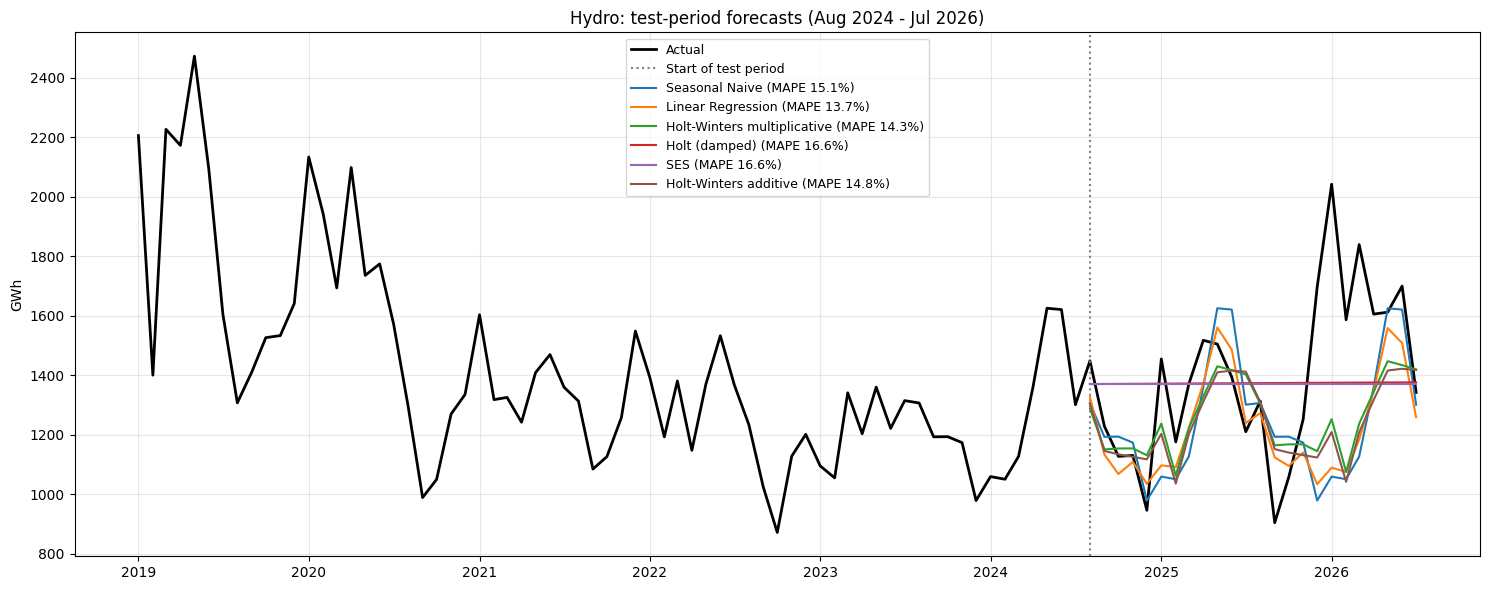

In [19]:
plot_forecasts("hydro", all_forecasts["hydro"], all_tables["hydro"])

**Hydro: model results**

* **Best model: Linear Regression** on lag features of year-on-year log change. MAPE 13.7%, MASE 0.983.
* The gain over the seasonal naive (MAPE 15.1%) is small: an **8% lower MAE**. Holt-Winters multiplicative is essentially tied (14.3%, MASE 0.991).
* Most models fall in a narrow 13.7–16.6% band, and SARIMA (15.8%) is no better than the baseline. Hydro has **no strong signal beyond its average seasonal shape**, and its deviations come from weather that the past cannot predict.
* The neural network is the worst model (18.9%). With fewer than 300 training rows it overfits.

### 5.2 Residual analysis of the best hydro model
The residuals are one-step-ahead errors over the 60 months before the test period, re-estimating the model each month. A good model leaves residuals with **mean ≈ 0**, **no autocorrelation** (Ljung-Box p > 0.05) and roughly normal shape.

Best hydro model on the test period: Linear Regression


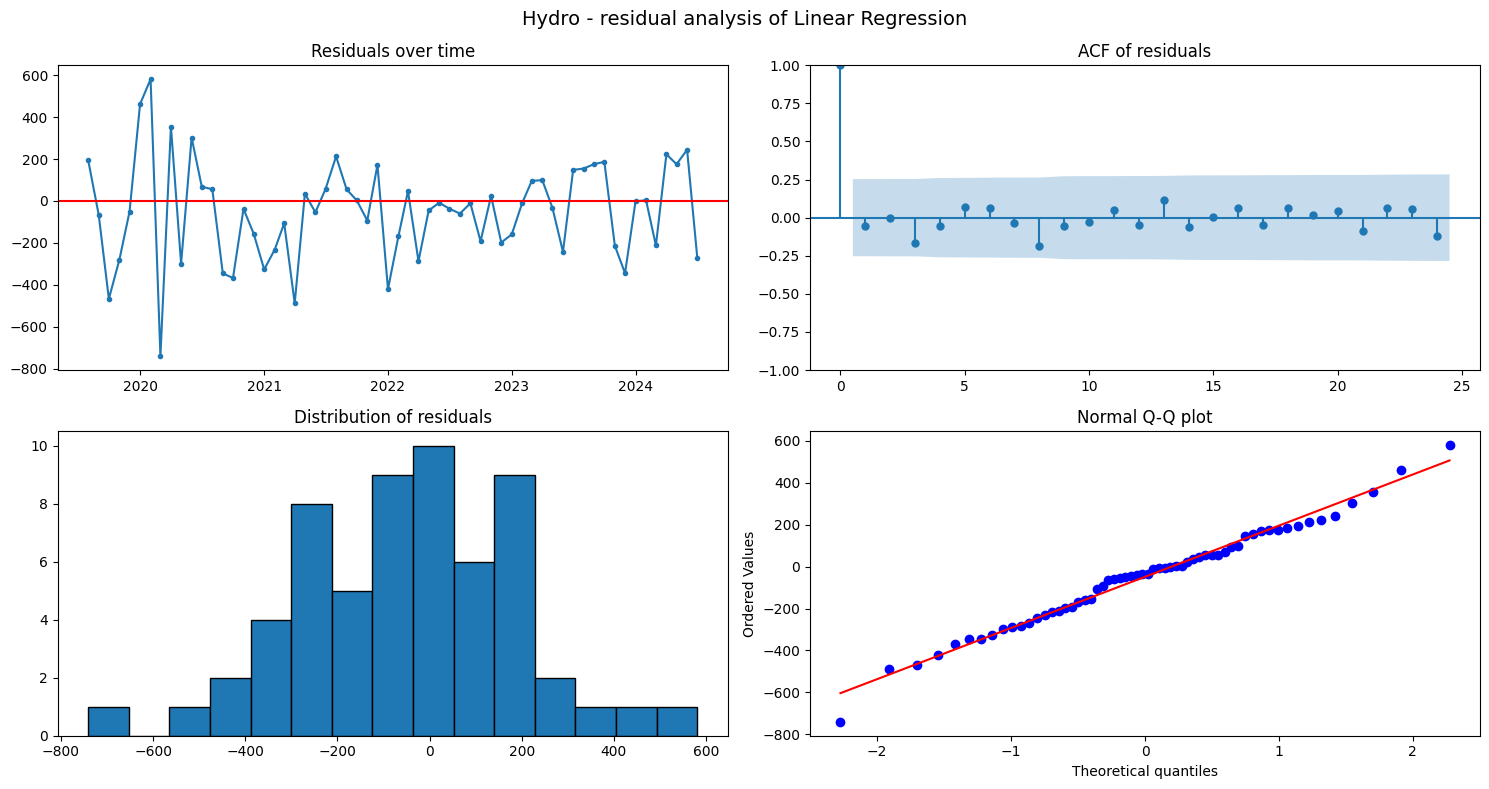

,resource,model,n,mean,mean t-test p,std,Ljung-Box p (lag 6),Ljung-Box p (lag 12),Shapiro-Wilk p
0,hydro,Linear Regression,60,-48.531,0.124,240.582,0.841,0.916,0.912


In [20]:
best_hydro = all_tables["hydro"].index[0]
print("Best hydro model on the test period:", best_hydro)
one_step_hydro, test_err_hydro = residual_analysis("hydro", best_hydro)
residual_rows.append(residual_report("hydro", best_hydro, one_step_hydro))
pd.DataFrame([residual_rows[-1]])

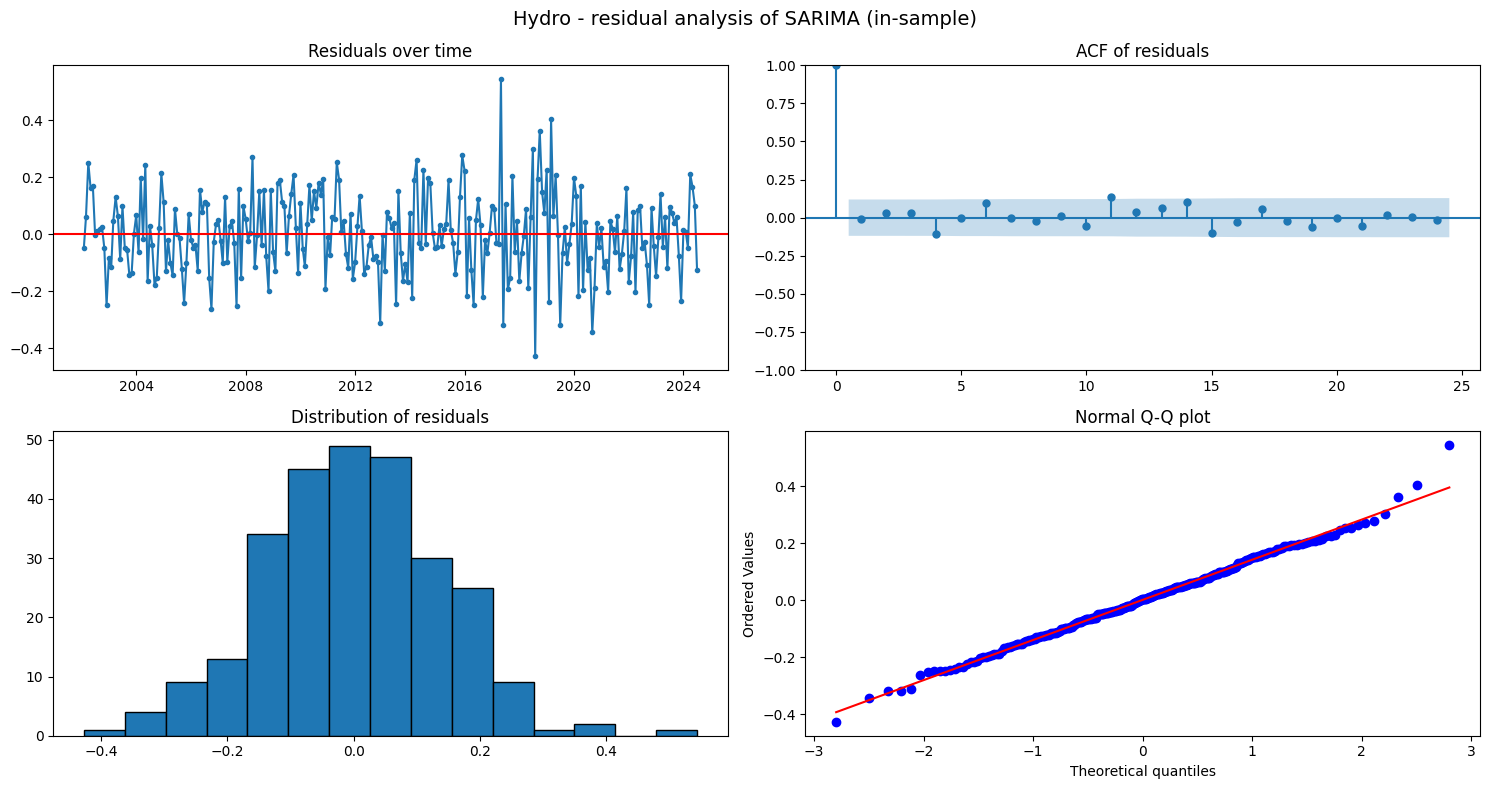

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5978      0.064      9.409      0.000       0.473       0.722
ma.L1         -0.9389      0.030    -31.239      0.000      -0.998      -0.880
ar.S.L12       0.7819      0.084      9.347      0.000       0.618       0.946
ma.S.L12      -0.5001      0.113     -4.421      0.000      -0.722      -0.278
sigma2         0.0192      0.001     13.043      0.000       0.016       0.022


,resource,model,n,mean,mean t-test p,std,Ljung-Box p (lag 6),Ljung-Box p (lag 12),Shapiro-Wilk p
0,hydro,SARIMA (in-sample),270,0.001,0.934,0.140,0.415,0.391,0.565


In [21]:
# For comparison: residuals of the SARIMA model fitted on the training data (in-sample, model scale)
o = orders["hydro"]["SARIMA"]
sarima_fit = ARIMA(to_model_scale(train["hydro"], "hydro"), order=o["order"], seasonal_order=o["seasonal_order"], trend=o["trend"]).fit()
sarima_resid = sarima_fit.resid.iloc[13:]
residual_rows.append(residual_report("hydro", "SARIMA (in-sample)", sarima_resid))
print(sarima_fit.summary().tables[1])
pd.DataFrame([residual_rows[-1]])

**Hydro: residual interpretation**

* **Linear Regression:** the mean one-step error (−49 GWh) is not significantly different from 0 (p = 0.12). There is **no autocorrelation** (Ljung-Box p = 0.84 at lag 6, 0.92 at lag 12) and the errors are normal (Shapiro p = 0.91). These are white-noise residuals.
* **SARIMA(1,1,1)(1,0,1)12 (log scale):** residual mean ≈ 0 (p = 0.93), no autocorrelation (Ljung-Box p = 0.42 and 0.39) and normal (Shapiro p = 0.57). Also white noise.

Both models capture the hydro series' time structure. What remains is unpredictable weather-driven variation, which explains why no model gets much below about 14% error.

## 6. Solar — separate models

### 6.1 Baseline, ARIMA/SARIMA/SARIMAX, Holt-Winters, ML and neural network (test period)

In [22]:
all_forecasts["solar"], all_tables["solar"] = run_all_models("solar")
all_tables["solar"]

,family,MAE,RMSE,MAPE,MASE
model,,,,,
SARIMAX (Fourier exog),SARIMAX,264.179,301.825,11.448,2.425
SARIMA,SARIMA,292.513,363.522,11.231,2.685
Random Forest,ML,365.426,425.685,15.084,3.354
Linear Regression,ML,525.964,597.499,20.162,4.828
ARIMA,ARIMA,551.134,625.316,19.211,5.059
Holt-Winters additive,Holt-Winters,788.118,1004.702,25.539,7.234
Holt-Winters add. damped,Holt-Winters,810.183,1046.296,25.689,7.436
Holt-Winters multiplicative,Holt-Winters,899.781,1054.277,28.642,8.259
Neural Network (MLP),Neural network,1082.258,1244.929,35.064,9.934


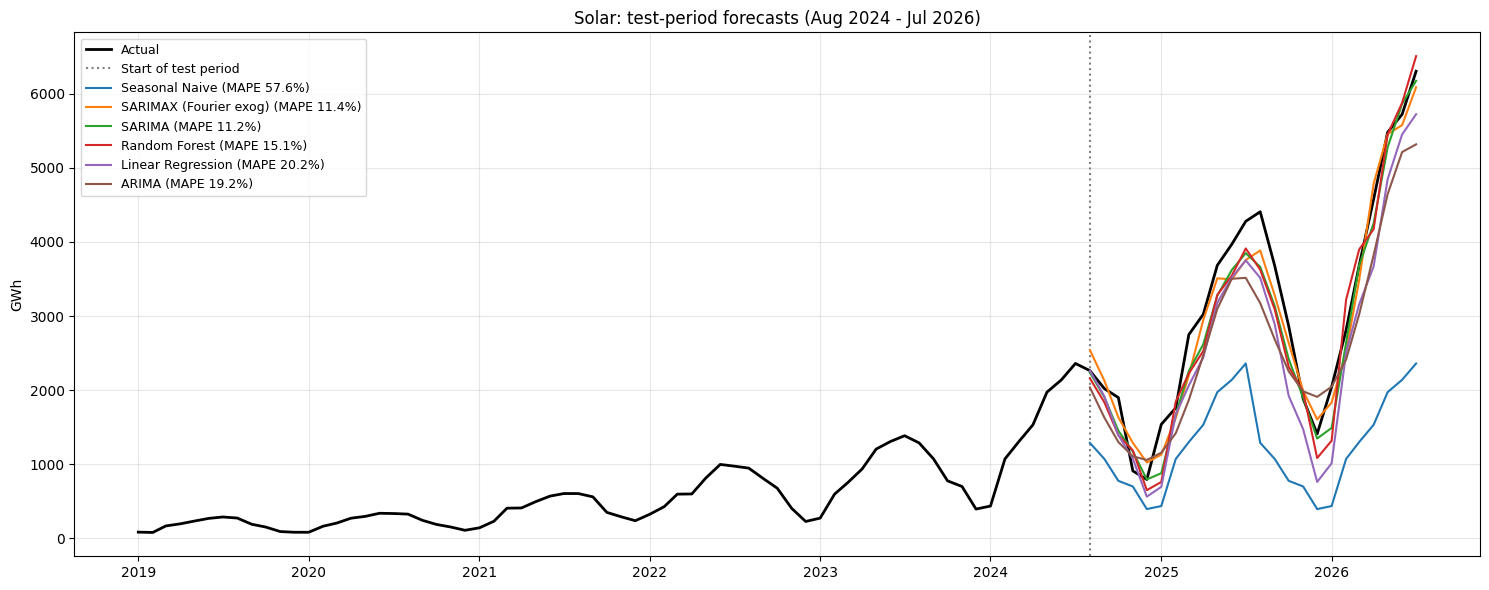

In [23]:
plot_forecasts("solar", all_forecasts["solar"], all_tables["solar"])

**Solar: model results**

* **Best model: SARIMAX**, an ARIMA(3,1,3) with drift plus Fourier seasonal terms, on log(solar). MAPE **11.9%**, an 84% lower MAE than the seasonal naive.
  **SARIMA(1,0,0)(1,1,1)12 with drift** is essentially tied (MAPE 11.2%, which is actually lower; MASE 2.69 vs 2.62).
* Random Forest is next (15.1%), then ARIMA (19.1%) and linear regression (20.2%).
* **Trend-free models fail badly:**
  * seasonal naive 57.6%;
  * naive and SES 47.2%;
  * damped Holt 54.2%.
  This **supports H3**: solar nearly doubled in 2025, and only models with an explicit growth (drift) term keep up.
* Holt-Winters (25.5–28.6%) and the neural network (35.1%) under-forecast the 2025–26 surge.
* The MASE values for solar are all above 1, because MASE is scaled by in-sample errors from years when solar was tiny. **MAPE is the meaningful comparison** here.

### 6.2 Residual analysis of the best solar model
The residuals are one-step-ahead errors over the 60 months before the test period, re-estimating the model each month. A good model leaves residuals with **mean ≈ 0**, **no autocorrelation** (Ljung-Box p > 0.05) and roughly normal shape.

Best solar model on the test period: SARIMAX (Fourier exog)


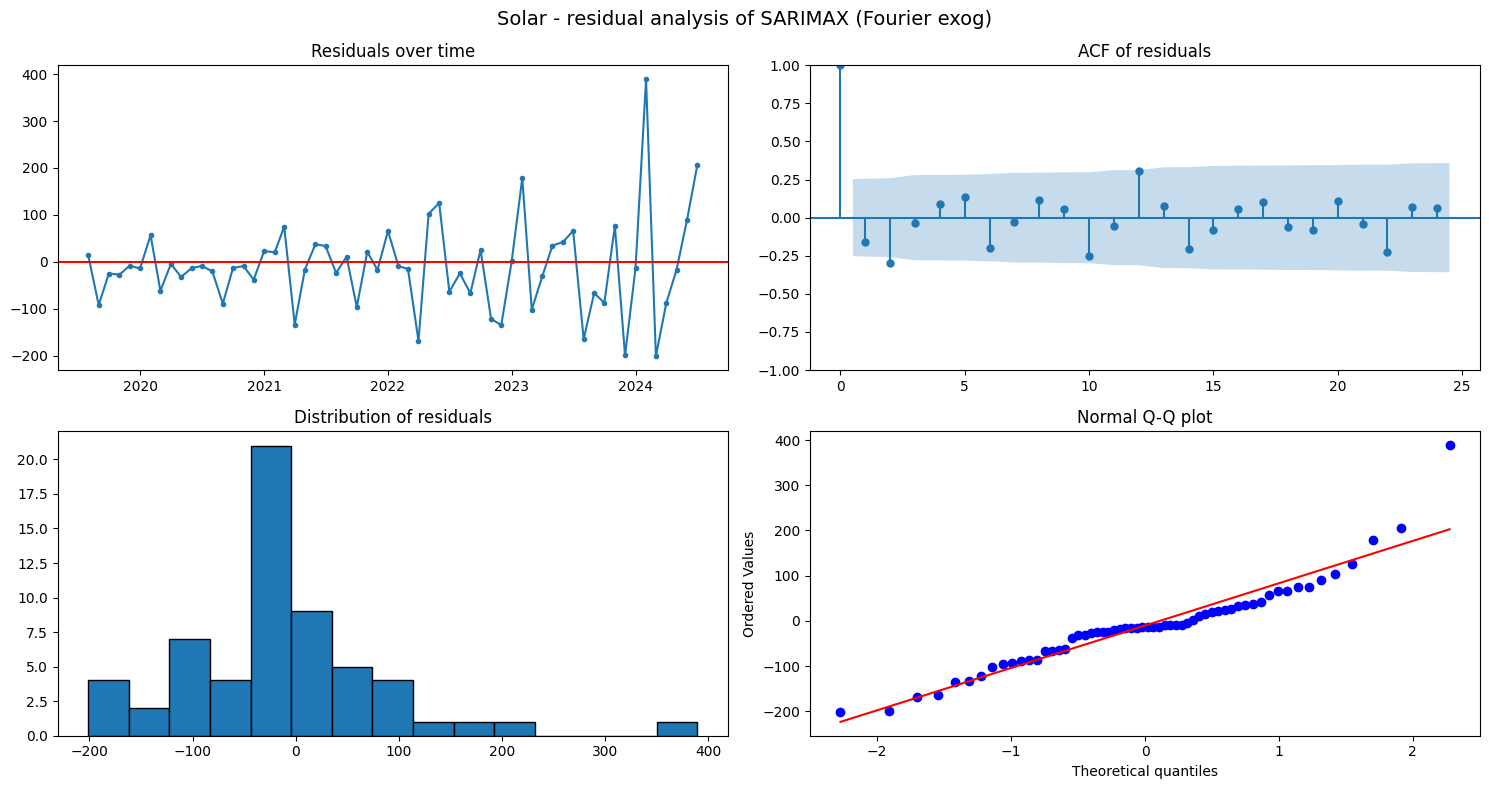

,resource,model,n,mean,mean t-test p,std,Ljung-Box p (lag 6),Ljung-Box p (lag 12),Shapiro-Wilk p
0,solar,SARIMAX (Fourier exog),60,-10.433,0.405,96.379,0.068,0.015,0.001


In [24]:
best_solar = all_tables["solar"].index[0]
print("Best solar model on the test period:", best_solar)
one_step_solar, test_err_solar = residual_analysis("solar", best_solar)
residual_rows.append(residual_report("solar", best_solar, one_step_solar))
pd.DataFrame([residual_rows[-1]])

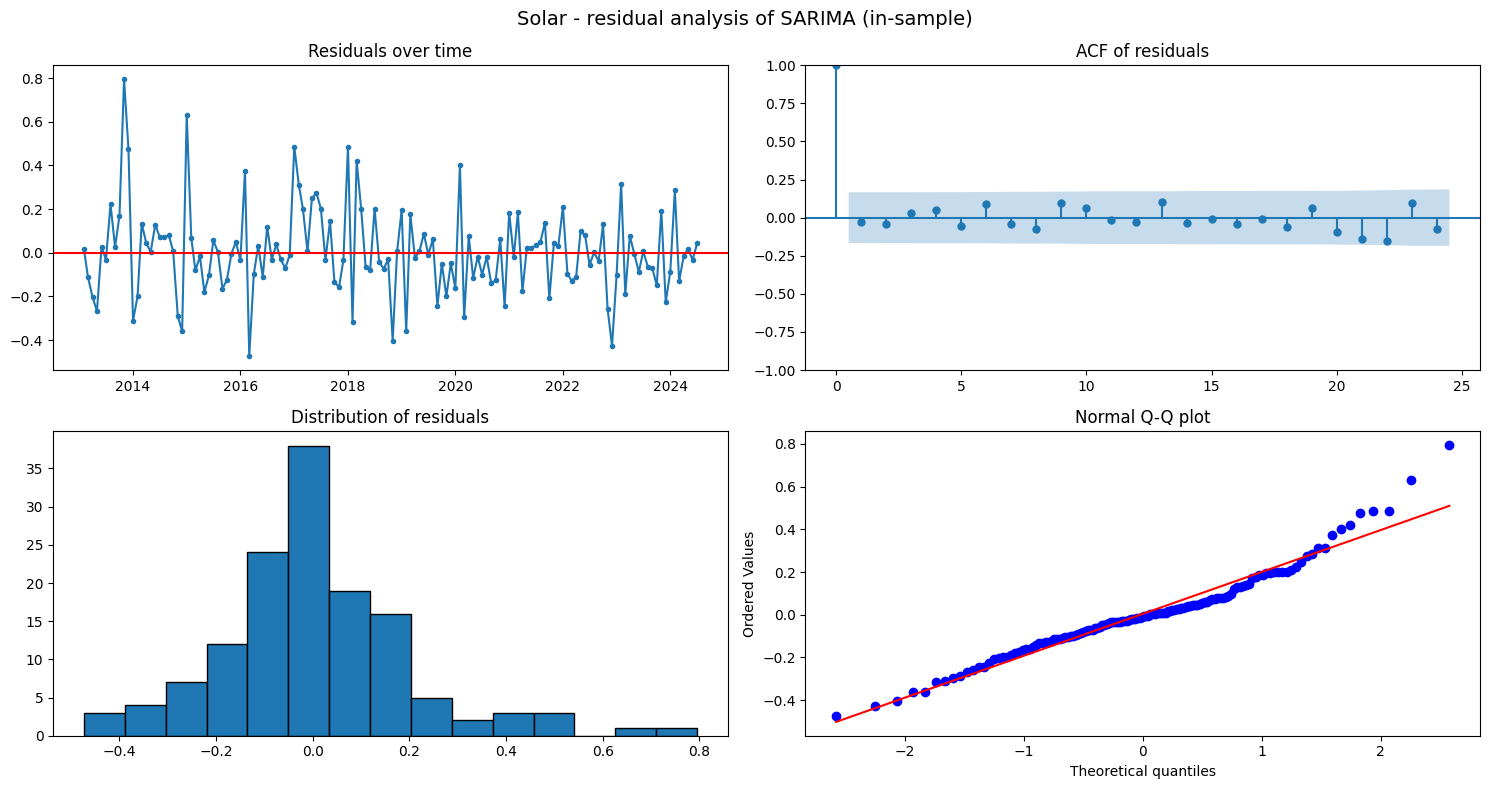

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1             0.0389      0.002     16.086      0.000       0.034       0.044
ar.L1          0.7733      0.051     15.083      0.000       0.673       0.874
ar.S.L12       0.2556      0.137      1.870      0.061      -0.012       0.524
ma.S.L12      -0.8322      0.149     -5.604      0.000      -1.123      -0.541
sigma2         0.0365      0.004      9.181      0.000       0.029       0.044


,resource,model,n,mean,mean t-test p,std,Ljung-Box p (lag 6),Ljung-Box p (lag 12),Shapiro-Wilk p
0,solar,SARIMA (in-sample),138,0.004,0.804,0.199,0.870,0.935,0.000


In [26]:
# For comparison: residuals of the SARIMA model fitted on the training data (in-sample, model scale)
o = orders["solar"]["SARIMA"]
sarima_fit = ARIMA(to_model_scale(train["solar"], "solar"), order=o["order"], seasonal_order=o["seasonal_order"], trend=o["trend"]).fit()
sarima_resid = sarima_fit.resid.iloc[13:]
residual_rows.append(residual_report("solar", "SARIMA (in-sample)", sarima_resid))
print(sarima_fit.summary().tables[1])
pd.DataFrame([residual_rows[-1]])

**Solar: residual interpretation**

* **SARIMAX (best on test):** the mean one-step error is ≈ 0 (p = 0.44), but Ljung-Box is significant at lag 12 (p = 0.017) and the errors are non-normal (Shapiro p = 0.001). Some seasonal dependence is left over.
* **SARIMA(1,0,0)(1,1,1)12 with drift:** residual mean ≈ 0 (p = 0.80) and **no autocorrelation** (Ljung-Box p = 0.87 and 0.94). These are white-noise residuals, non-normal only because of a few unusual months.
  The drift coefficient (shown as `x1`, about 0.039 per month on the log scale) corresponds to roughly **4% growth per month, about 59% per year**.

SARIMA matches SARIMAX's accuracy and leaves cleaner residuals, so **SARIMA is the more reliable solar model**.

## 7. Biomass — separate models

### 7.1 Baseline, ARIMA/SARIMA/SARIMAX, Holt-Winters, ML and neural network (test period)

In [27]:
all_forecasts["biomass"], all_tables["biomass"] = run_all_models("biomass")
all_tables["biomass"]

,family,MAE,RMSE,MAPE,MASE
model,,,,,
Seasonal Naive,Baseline,21.601,27.114,4.626,0.541
Holt-Winters multiplicative,Holt-Winters,22.639,29.055,4.843,0.567
Holt-Winters add. damped,Holt-Winters,23.148,29.276,4.943,0.580
Holt-Winters additive,Holt-Winters,23.172,29.306,4.948,0.581
Neural Network (MLP),Neural network,23.503,28.794,5.275,0.589
Linear Regression,ML,24.236,30.420,5.389,0.607
SARIMAX (Fourier exog),SARIMAX,25.085,31.769,5.323,0.629
Random Forest,ML,25.170,31.638,5.676,0.631
ARIMA,ARIMA,26.561,35.690,5.742,0.666


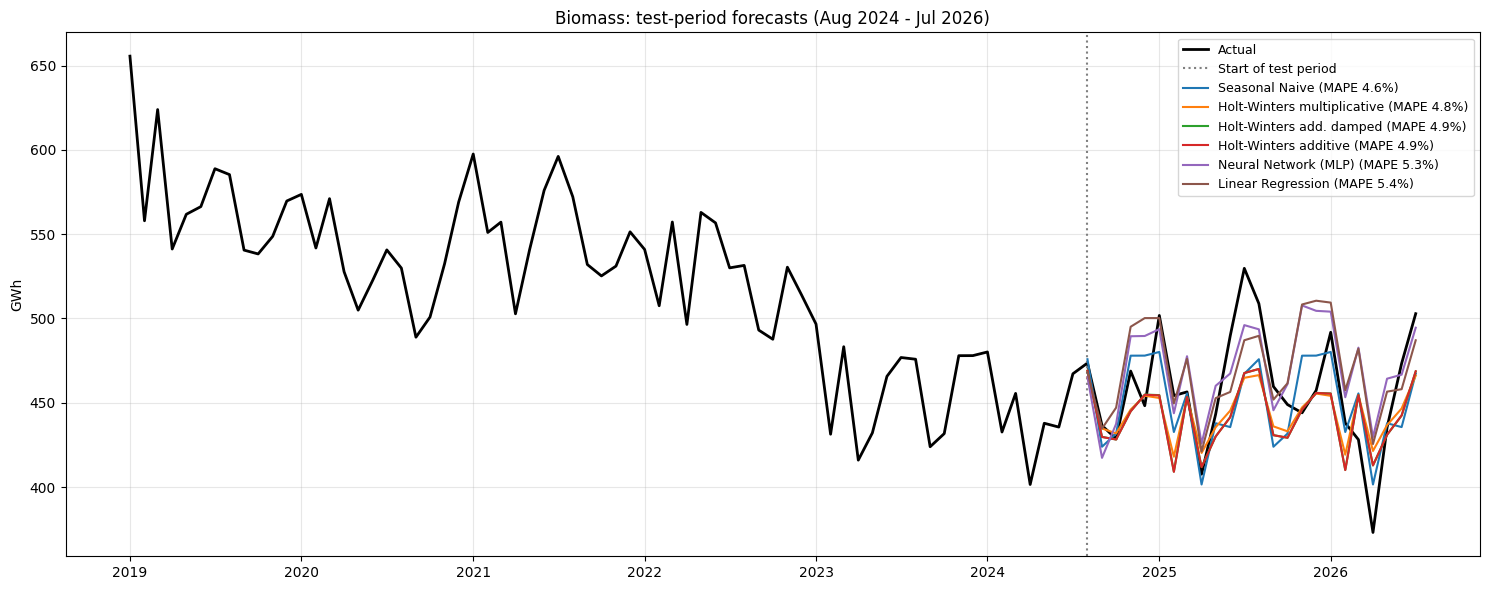

In [25]:
plot_forecasts("biomass", all_forecasts["biomass"], all_tables["biomass"])

**Biomass: model results**

* **Best model: Seasonal Naive** (each month equals the same month last year). MAPE **4.6%**, MASE 0.541.
* No model beats it. Holt-Winters multiplicative (4.8%), the neural network (5.3%), SARIMAX (5.3%) and linear regression (5.4%) come close.
* **SARIMA is the weakest model (7.9%).** Its estimated seasonal AR coefficient is almost 1 (0.98), so it effectively repeats last year, and then its ARMA terms add a downward drift that over-shoots.
* **H2 is therefore not supported for biomass.** Midwestern biomass is so stable from year to year that the simplest seasonal benchmark is the best forecast.

### 7.2 Residual analysis of the best biomass model
The residuals are one-step-ahead errors over the 60 months before the test period, re-estimating the model each month. A good model leaves residuals with **mean ≈ 0**, **no autocorrelation** (Ljung-Box p > 0.05) and roughly normal shape.

Best biomass model on the test period: Seasonal Naive


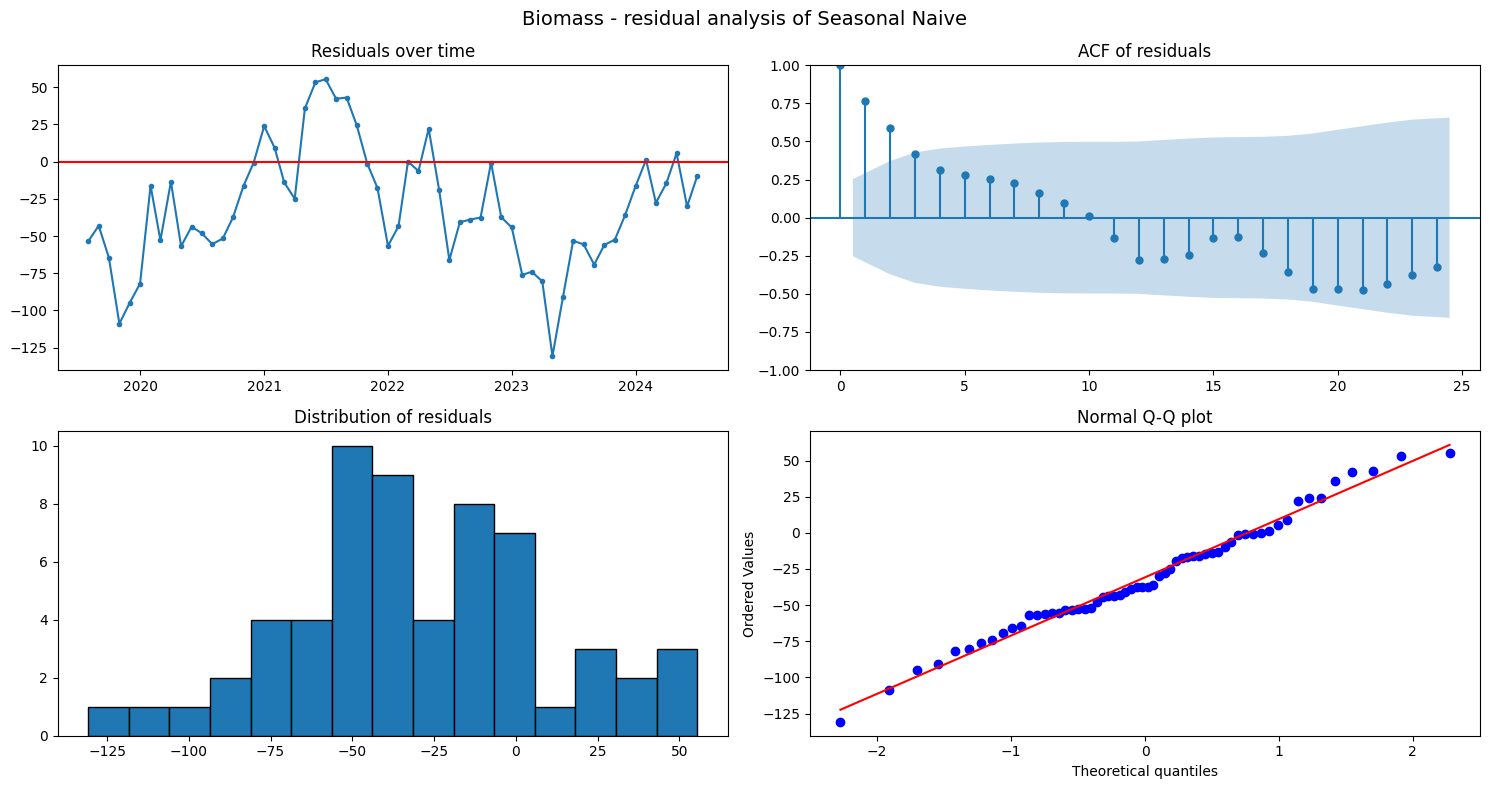

,resource,model,n,mean,mean t-test p,std,Ljung-Box p (lag 6),Ljung-Box p (lag 12),Shapiro-Wilk p
0,biomass,Seasonal Naive,60,-30.761,0.000,39.645,0.000,0.000,0.733


In [28]:
best_biomass = all_tables["biomass"].index[0]
print("Best biomass model on the test period:", best_biomass)
one_step_biomass, test_err_biomass = residual_analysis("biomass", best_biomass)
residual_rows.append(residual_report("biomass", best_biomass, one_step_biomass))
pd.DataFrame([residual_rows[-1]])

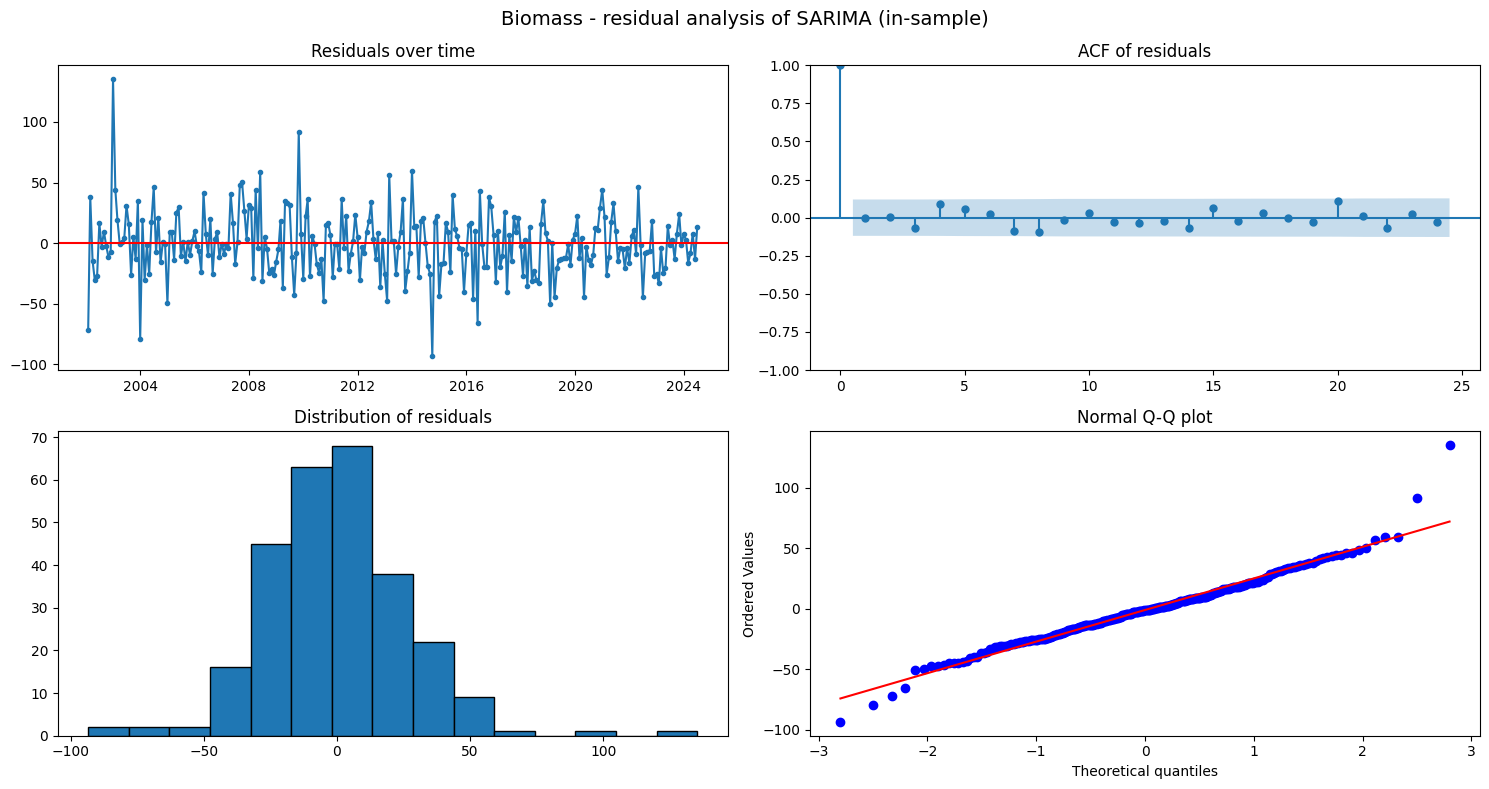

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3233      0.136      2.375      0.018       0.057       0.590
ma.L1         -0.6854      0.108     -6.321      0.000      -0.898      -0.473
ar.S.L12       0.9824      0.013     74.456      0.000       0.957       1.008
ma.S.L12      -0.8214      0.056    -14.577      0.000      -0.932      -0.711
sigma2       649.1225     39.735     16.336      0.000     571.244     727.001


,resource,model,n,mean,mean t-test p,std,Ljung-Box p (lag 6),Ljung-Box p (lag 12),Shapiro-Wilk p
0,biomass,SARIMA (in-sample),270,-0.995,0.536,26.386,0.613,0.613,0.000


In [30]:
# For comparison: residuals of the SARIMA model fitted on the training data (in-sample, model scale)
o = orders["biomass"]["SARIMA"]
sarima_fit = ARIMA(to_model_scale(train["biomass"], "biomass"), order=o["order"], seasonal_order=o["seasonal_order"], trend=o["trend"]).fit()
sarima_resid = sarima_fit.resid.iloc[13:]
residual_rows.append(residual_report("biomass", "SARIMA (in-sample)", sarima_resid))
print(sarima_fit.summary().tables[1])
pd.DataFrame([residual_rows[-1]])

**Biomass: residual interpretation**

* **Seasonal Naive (best on test):** the one-step errors have a **significantly negative mean** (−31 GWh, p < 0.001). The benchmark **over-forecasts**, because biomass kept declining while the forecast copies last year's higher values. The errors are also **autocorrelated** (Ljung-Box p < 0.001) but normal (Shapiro p = 0.73).
* **SARIMA(1,1,1)(1,0,1)12 in-sample:** residual mean ≈ 0 (p = 0.54) and no autocorrelation (Ljung-Box p = 0.61 at lags 6 and 12). These are white noise in-sample, although the model forecast the test period worse.

The seasonal naive is the most accurate biomass forecast, but its biased, autocorrelated errors show it ignores the ongoing decline. A small downward adjustment would likely improve it.

### 7.3 Wind

In [31]:
all_forecasts["wind"], all_tables["wind"] = run_all_models("wind")
all_tables["wind"]

,family,MAE,RMSE,MAPE,MASE
model,,,,,
Holt-Winters multiplicative,Holt-Winters,1152.714,1500.856,8.074,1.278
Seasonal Naive,Baseline,1196.798,1710.383,7.720,1.327
Holt-Winters additive,Holt-Winters,1723.654,2112.420,12.886,1.911
Holt-Winters add. damped,Holt-Winters,1787.699,2183.828,13.381,1.982
SARIMA,SARIMA,2589.414,3035.696,17.651,2.871
ARIMA,ARIMA,3406.732,4302.045,20.370,3.777
SARIMAX (Fourier exog),SARIMAX,4274.466,5045.409,28.452,4.739
Random Forest,ML,5494.918,6058.066,37.594,6.092
Holt (damped),Exponential smoothing,6547.300,7538.311,37.781,7.259


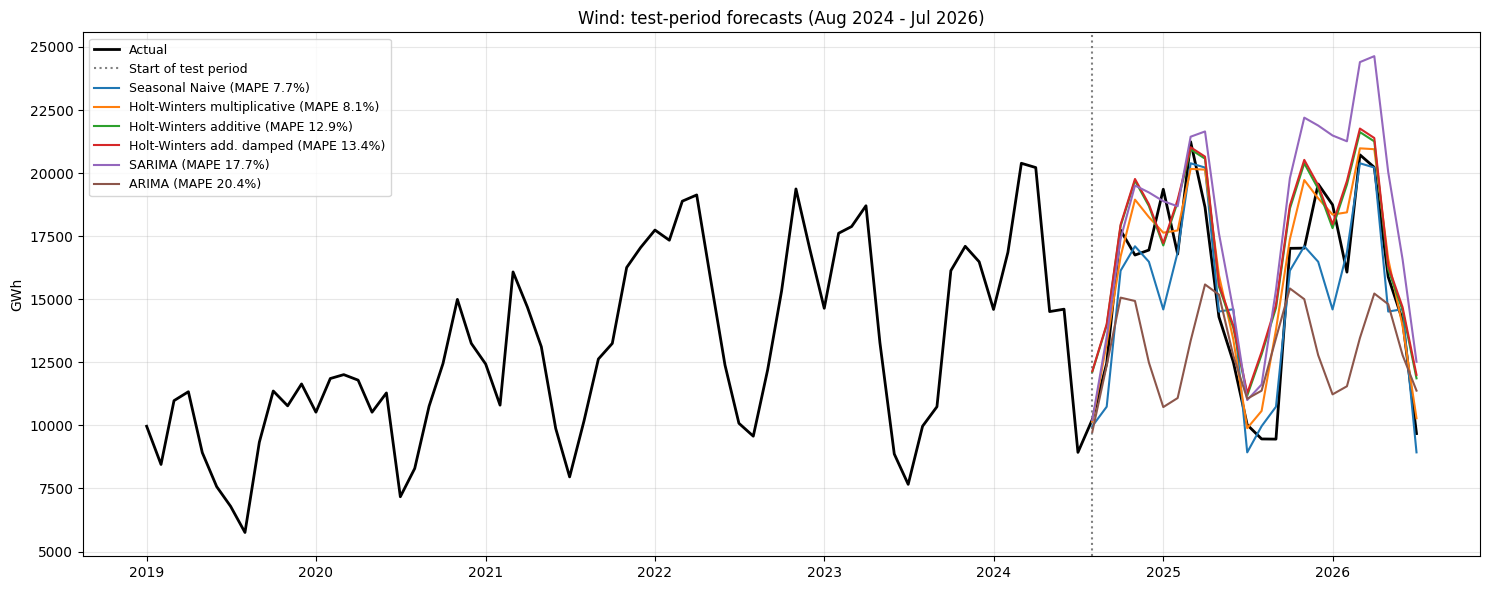

In [33]:
plot_forecasts("wind", all_forecasts["wind"], all_tables["wind"])

Best wind model on the test period: Holt-Winters multiplicative


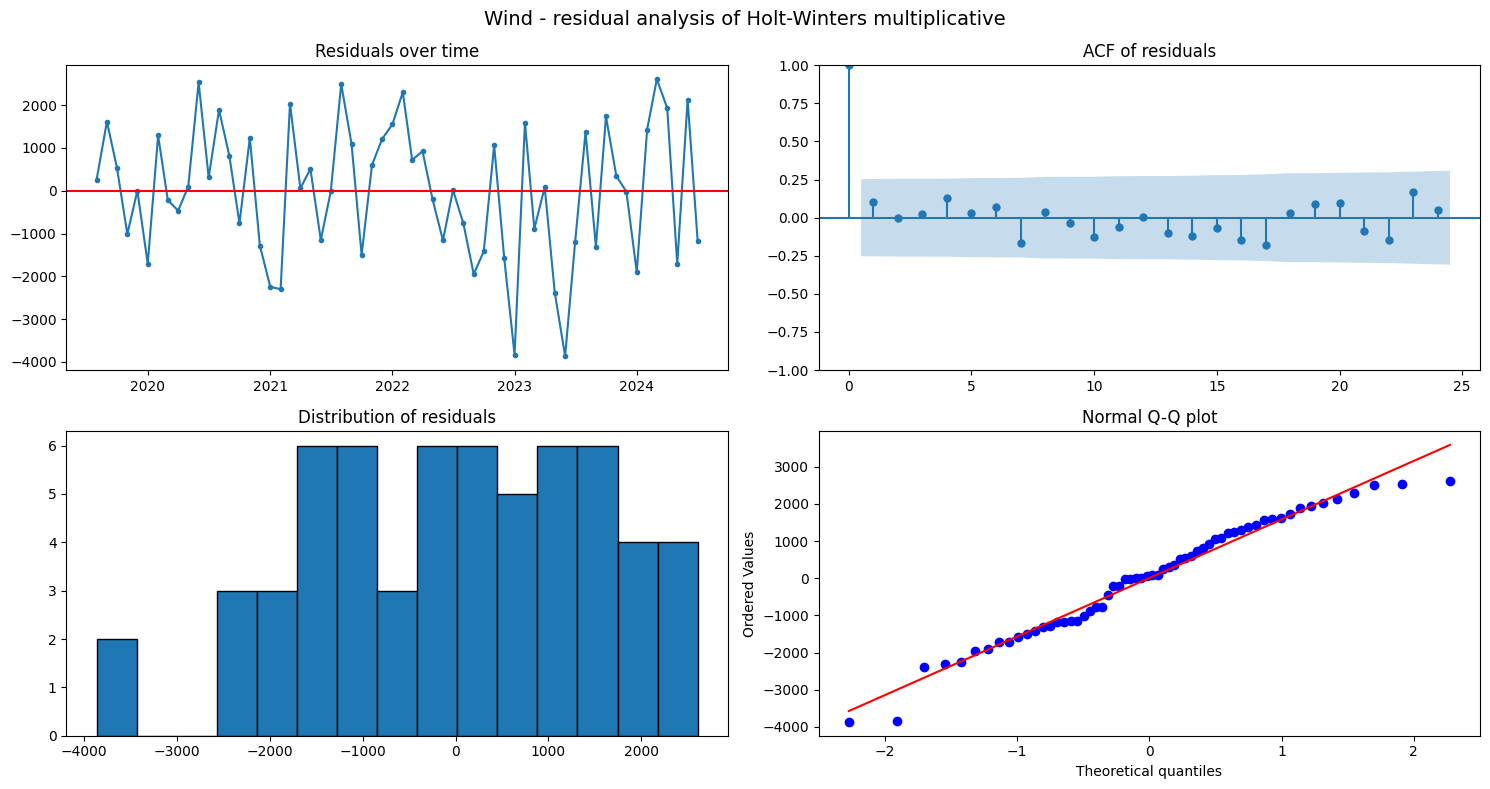

,resource,model,n,mean,mean t-test p,std,Ljung-Box p (lag 6),Ljung-Box p (lag 12),Shapiro-Wilk p
0,wind,Holt-Winters multiplicative,60,6.258,0.975,1557.363,0.899,0.926,0.179


In [34]:
best_wind = all_tables["wind"].index[0]
print("Best wind model on the test period:", best_wind)
one_step_wind, test_err_wind = residual_analysis("wind", best_wind)
residual_rows.append(residual_report("wind", best_wind, one_step_wind))
pd.DataFrame([residual_rows[-1]])

## 8. Model comparison across resources

In [35]:
summary_rows = []
for r in RESOURCES:
    t = all_tables[r]
    for family in ["Baseline", "ARIMA", "SARIMA", "SARIMAX", "Exponential smoothing", "Holt-Winters", "ML", "Neural network"]:
        best_in_family = t[t.family == family].sort_values("MASE").iloc[0]
        summary_rows.append({"resource": r, "family": family, "model": best_in_family.name,
                             "MAPE": best_in_family.MAPE, "MASE": best_in_family.MASE})
summary = pd.DataFrame(summary_rows)

print("MAPE (%) of the best model in each family:")
mape_table = summary.pivot(index="resource", columns="family", values="MAPE")
mape_table["Best model"] = [all_tables[r].index[0] for r in mape_table.index]
display(mape_table)

print("MASE of the best model in each family (lower is better, < 1 beats seasonal naive in-sample):")
display(summary.pivot(index="resource", columns="family", values="MASE"))

MAPE (%) of the best model in each family:


family,ARIMA,Baseline,Exponential smoothing,Holt-Winters,ML,Neural network,SARIMA,SARIMAX,Best model
resource,,,,,,,,,
biomass,5.742,4.626,5.760,4.843,5.389,5.275,7.945,5.323,Seasonal Naive
hydro,15.162,15.087,16.569,14.276,13.668,18.865,15.843,15.803,Linear Regression
solar,19.211,47.195,54.241,25.539,15.084,35.064,11.231,11.448,SARIMAX (Fourier exog)
wind,20.370,7.720,37.781,8.074,37.594,86.005,17.651,28.452,Holt-Winters multiplicative


MASE of the best model in each family (lower is better, < 1 beats seasonal naive in-sample):


family,ARIMA,Baseline,Exponential smoothing,Holt-Winters,ML,Neural network,SARIMA,SARIMAX
resource,,,,,,,,
biomass,0.666,0.541,0.669,0.567,0.607,0.589,0.944,0.629
hydro,1.055,1.068,1.031,0.991,0.983,1.300,1.120,1.113
solar,5.059,11.953,10.675,7.234,3.354,9.934,2.685,2.425
wind,3.777,1.327,7.259,1.278,6.092,14.725,2.871,4.739


In [36]:
best_overall = pd.DataFrame({
    r: {"best model": all_tables[r].index[0],
        "best MAPE %": all_tables[r].MAPE.iloc[0],
        "best MASE": all_tables[r].MASE.iloc[0],
        "Seasonal Naive MAPE %": all_tables[r].loc["Seasonal Naive", "MAPE"],
        "improvement over Seasonal Naive (MAE) %": (1 - all_tables[r].MAE.iloc[0] / all_tables[r].loc["Seasonal Naive", "MAE"]) * 100}
    for r in RESOURCES}).T
best_overall

,best model,best MAPE %,best MASE,Seasonal Naive MAPE %,improvement over Seasonal Naive (MAE) %
hydro,Linear Regression,13.668,0.983,15.087,7.968
solar,SARIMAX (Fourier exog),11.448,2.425,57.612,85.477
biomass,Seasonal Naive,4.626,0.541,4.626,0.000
wind,Holt-Winters multiplicative,8.074,1.278,7.720,3.684


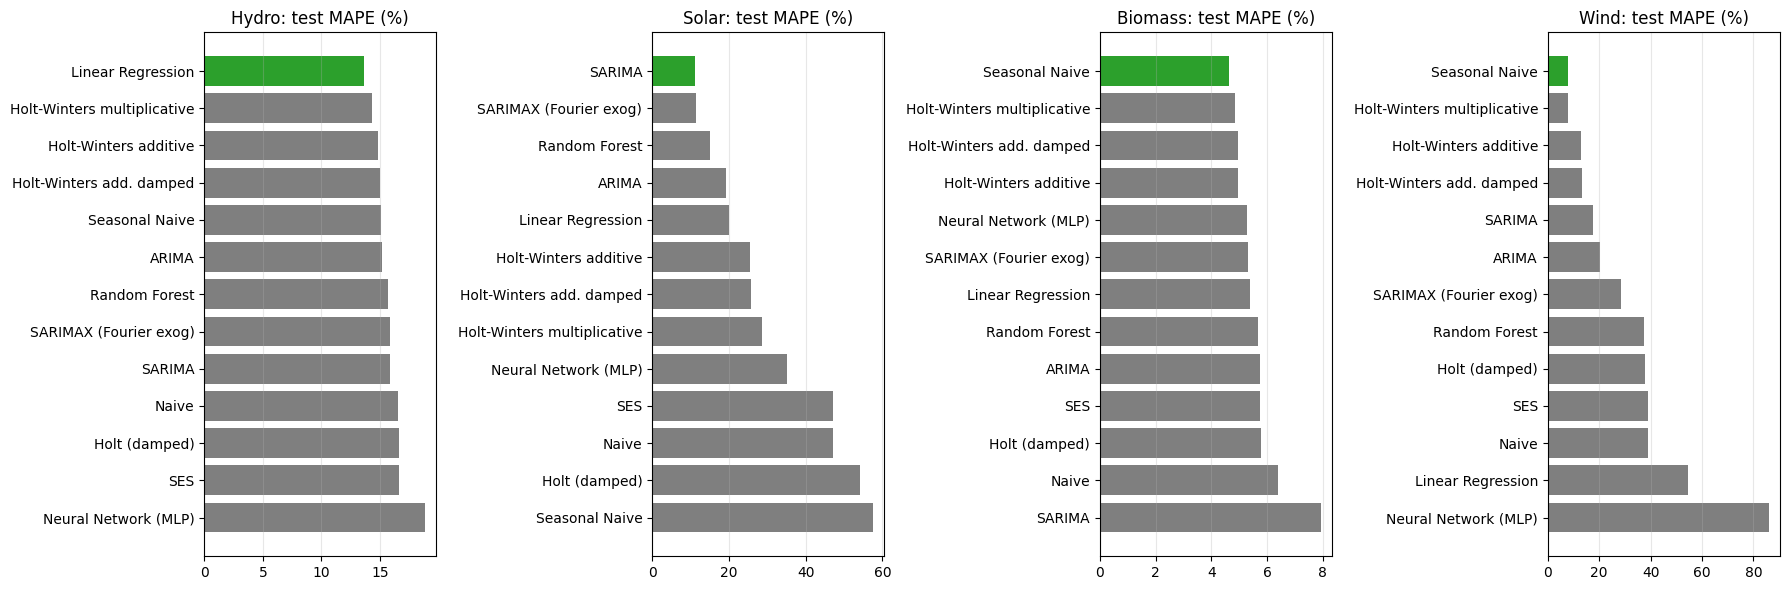

In [37]:
fig, axes = plt.subplots(1, 4, figsize=(18, 6))
for ax, r in zip(axes, RESOURCES):
    t = all_tables[r].sort_values("MAPE")
    ax.barh(t.index, t.MAPE, color=["tab:green" if i == 0 else "tab:gray" for i in range(len(t))])
    ax.invert_yaxis()
    ax.set_title(f"{r.capitalize()}: test MAPE (%)")
    ax.grid(True, alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

## Model Comparison Across Resources

| Resource | Best Model | Best Model MAPE | Seasonal Naive MAPE | Improvement in MAE |
|---|---|---:|---:|---:|
| Biomass | Seasonal Naive | **4.6%** | 4.6% | 0% (the benchmark itself) |
| Solar | SARIMAX (Fourier exog) | **11.45%** | 57.6% | **85.6%** |
| Hydro | Linear Regression | **13.7%** | 15.1% | **8.0%** |
| Wind | Holt–Winters multiplicative | **8.07%** | 7.72% | **3.7%** |

*Note: Solar's SARIMAX model has a MAPE of 11.45%, while SARIMA achieves a slightly lower MAPE of 11.23%. SARIMAX is selected based on its lower MAE and RMSE. Wind's Seasonal Naive model has a slightly lower MAPE than Holt–Winters multiplicative.*

### Key Findings

- **Each resource has a different best-performing model**, supporting the need to model each resource separately.
- **Difficulty:** Biomass is the easiest to forecast in relative terms, with a MAPE of 4.6%. Wind follows at 7.7–8.1%, Solar at approximately 11–12%, and Hydro at approximately 14–15%. These results describe performance on the selected test period rather than inherent forecasting difficulty across all periods.
- **H2 — Seasonal models beat the baseline:**
  - Supported for Solar: SARIMA achieves 11.23% MAPE versus 57.6% for Seasonal Naive.
  - Weakly supported for Hydro: Holt–Winters multiplicative achieves 14.28% MAPE versus 15.09% for Seasonal Naive.
  - Not supported for Biomass: Seasonal Naive itself is the best-performing model.
  - Mixed for Wind: Holt–Winters multiplicative has better MAE and RMSE, but Seasonal Naive has slightly better MAPE.
- **H3 — Solar needs growth-aware models:** Supported by the results. SARIMA and SARIMAX achieve approximately 11–12% MAPE, substantially better than the trend-free models, which have MAPE values around 19–20% for ARIMA and Linear Regression and higher values for some other methods. This supports the usefulness of seasonal and trend-aware modeling, although it does not isolate growth as the sole cause of improvement.
- **H4 — Forecastability differs across resources:** The results support differences in forecasting performance across resources. Biomass is easiest in this test period, while Hydro is harder in relative terms than Biomass and Wind. This is consistent with the hypothesis, but the results alone do not prove that weather variability causes Hydro's errors.

### Conclusion

No single model performs best for every renewable energy resource. Seasonal Naive is sufficient for Biomass, SARIMAX is strongest for Solar by MAE and RMSE, Linear Regression is strongest for Hydro by MAE, and Holt–Winters multiplicative is strongest for Wind by MAE and RMSE. Model selection should therefore be resource-specific and consider multiple evaluation metrics.

## 9. Forecast of the next 12 months (Aug 2026 – Jul 2027)
The best model of each resource is re-fitted on **all** data up to Jul 2026 and forecasts the next 12 months. The band is an approximate 90% range taken from that model's test-period percentage errors.

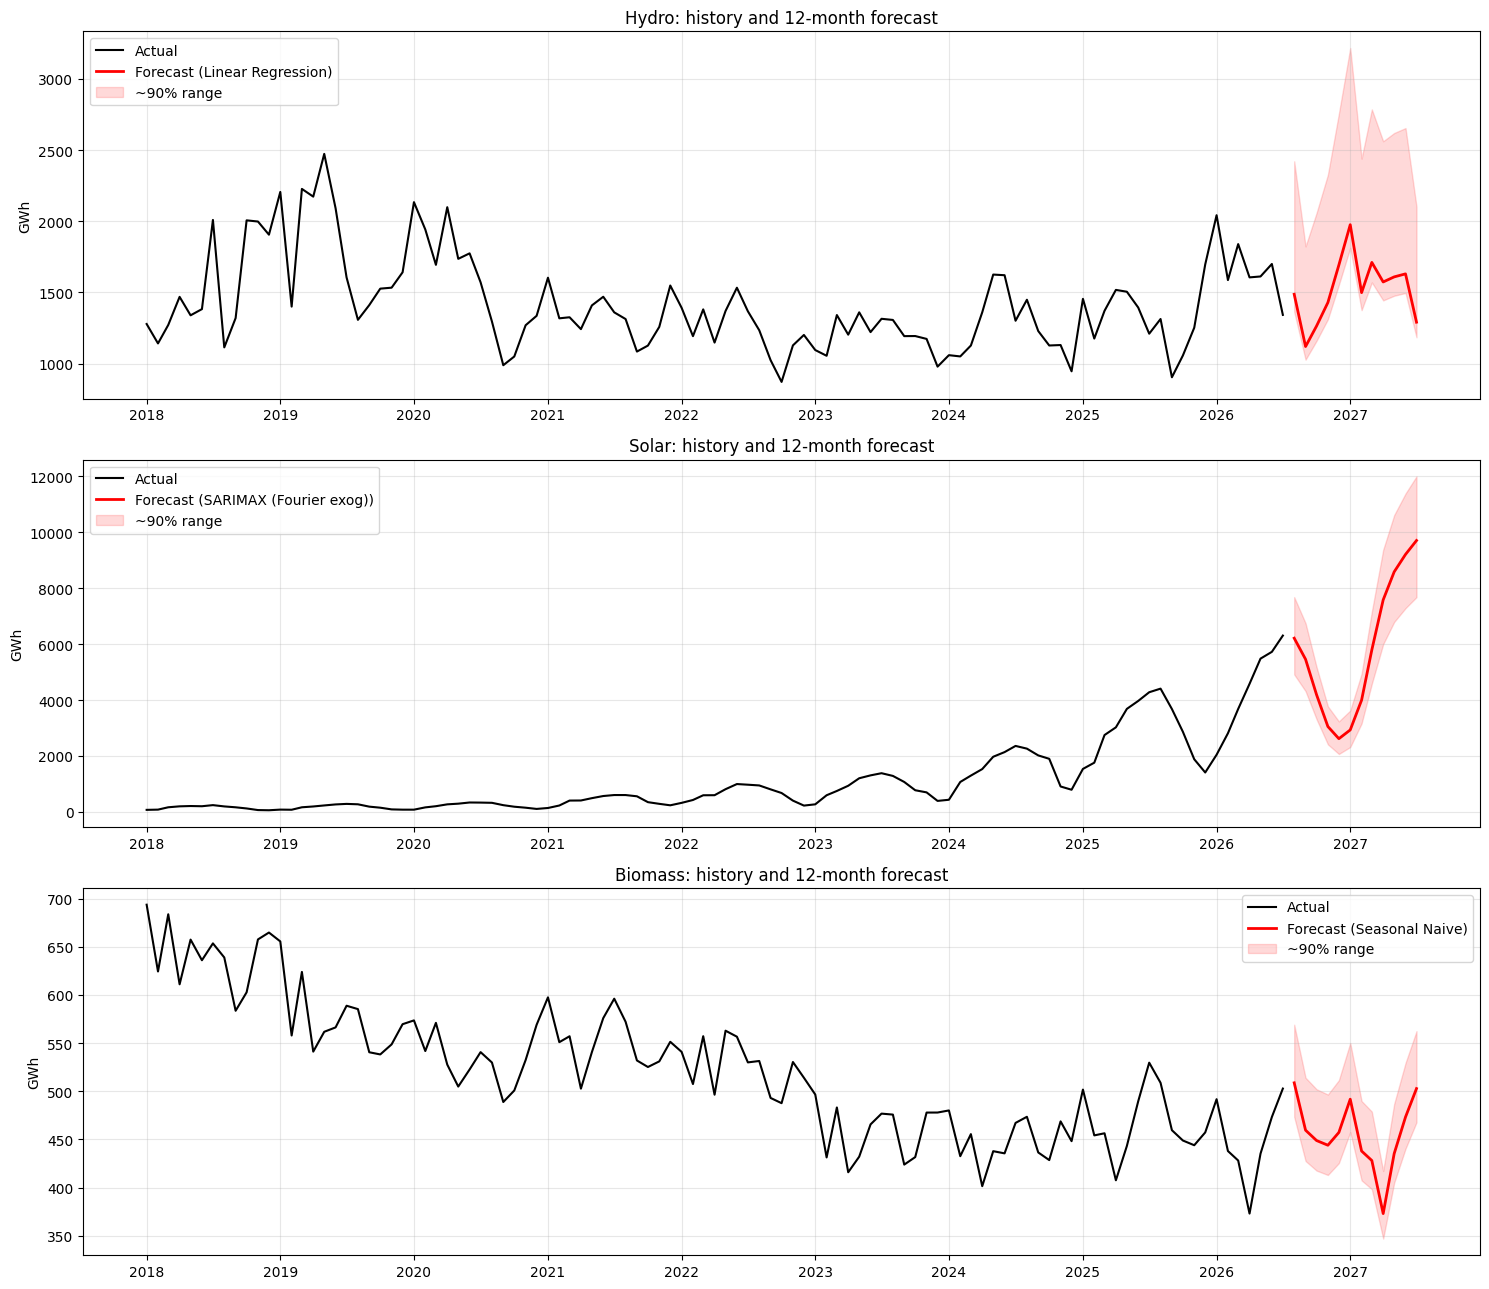

,best model,last 12 months (GWh),next 12 months forecast (GWh),change %,peak month,lowest month,"share of hydro+solar+biomass, next 12 m (%)"
hydro,Linear Regression,17953.450,18282.999,1.836,Jan 2027,Sep 2026,6.287
solar,SARIMAX (Fourier exog),44860.454,69300.422,54.480,Jul 2027,Dec 2026,23.829
biomass,Seasonal Naive,5461.279,5461.279,0.000,Aug 2026,Apr 2027,1.878
wind,Holt-Winters multiplicative,188025.812,197774.952,5.185,Mar 2027,Aug 2026,68.006


In [38]:
future = {}
for r in RESOURCES:
    best = all_tables[r].index[0]
    fc = MODELS[best][1](series[r], H_FUTURE, r)
    idx = pd.date_range(series[r].index[-1] + pd.offsets.MonthBegin(), periods=H_FUTURE, freq="MS")
    pct_err = (test[r] - all_forecasts[r][best]) / all_forecasts[r][best]
    lo, hi = np.quantile(pct_err, [0.05, 0.95])
    future[r] = pd.DataFrame({"forecast": fc, "lower_90": fc * (1 + lo), "upper_90": fc * (1 + hi)}, index=idx)

fig, axes = plt.subplots(3, 1, figsize=(15, 13))
for ax, r in zip(axes, RESOURCES):
    ax.plot(series[r].loc["2018-01-01":], color="black", label="Actual")
    ax.plot(future[r].forecast, color="red", linewidth=2, label=f"Forecast ({all_tables[r].index[0]})")
    ax.fill_between(future[r].index, future[r].lower_90, future[r].upper_90, color="red", alpha=0.15, label="~90% range")
    ax.set_title(f"{r.capitalize()}: history and 12-month forecast")
    ax.set_ylabel("GWh")
    ax.legend()
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

outlook = pd.DataFrame({
    r: {"best model": all_tables[r].index[0],
        "last 12 months (GWh)": series[r].iloc[-12:].sum(),
        "next 12 months forecast (GWh)": future[r].forecast.sum(),
        "change %": (future[r].forecast.sum() / series[r].iloc[-12:].sum() - 1) * 100,
        "peak month": future[r].forecast.idxmax().strftime("%b %Y"),
        "lowest month": future[r].forecast.idxmin().strftime("%b %Y")}
    for r in RESOURCES}).T
outlook["share of hydro+solar+biomass, next 12 m (%)"] = (
    outlook["next 12 months forecast (GWh)"].astype(float) / outlook["next 12 months forecast (GWh)"].astype(float).sum() * 100)
outlook

In [39]:
print("Monthly forecasts (GWh):")
pd.DataFrame({r: future[r].forecast for r in RESOURCES}).round(1)

Monthly forecasts (GWh):


,hydro,solar,biomass,wind
2026-08-01,1487.100,6209.500,508.800,10205.100
2026-09-01,1120.000,5455.600,459.600,13134.100
2026-10-01,1264.000,4191.200,448.900,17271.200
2026-11-01,1429.300,3052.000,444.000,18661.200
2026-12-01,1692.800,2618.600,457.300,18921.200
2027-01-01,1975.800,2931.100,491.800,18810.200
2027-02-01,1498.600,3994.900,438.000,18220.700
2027-03-01,1711.000,5790.900,428.100,20779.100
2027-04-01,1573.600,7577.400,373.100,20418.000
2027-05-01,1609.200,8578.600,435.300,17002.000


**Forecast for Aug 2026 – Jul 2027**

| Resource | Last 12 months | Forecast next 12 months | Change | Peak | Low |
|---|---:|---:|---:|---|---|
| Solar | 44,860 GWh | **70,216 GWh** | **+56.5%** | Jul 2027 | Dec 2026 |
| Hydro | 17,953 GWh | 18,283 GWh | +1.8% | Jan 2027 | Sep 2026 |
| Biomass | 5,461 GWh | 5,461 GWh | 0.0% | Aug 2026 | Apr 2027 |
| Wind | 188,026 GWh | **197,775 GWh** | **+5.2%** | Mar 2027 | Aug 2026 |

- **Solar** continues its steep growth and would supply about **75% of the region's combined hydro + solar + biomass output** next year. The +56.5% comes from extending the recent drift of about 4% per month. If new solar capacity slows, the true growth will be lower.
- **Hydro** is expected to stay roughly flat (+1.8%).
- **Biomass** is forecast by the Seasonal Naive model, so it repeats the last 12 months exactly (0% change). Given the residual analysis, a small decline is more likely.
- **Wind** is forecast to increase by approximately **5.2%**, from 188,026 GWh to 197,775 GWh, indicating moderate growth compared with the much steeper projected solar increase.

## 10. Geothermal

Geothermal generation is **0 GWh in every month from Jan 2001 to Jul 2026** in all 12 Midwestern states (Review 1, section 2).
There are no utility-scale geothermal plants in the region, so there is no time-series behaviour to model. Every model would forecast
exactly 0. The forecast for geothermal is therefore **0 GWh**, unless a new plant is built, which cannot be predicted from this data.

In [30]:
print("Geothermal generation in the Midwest: min =", region["geothermal"].min(), "| max =", region["geothermal"].max(),
      "| months > 0 =", int((region["geothermal"] > 0).sum()))

Geothermal generation in the Midwest: min = 0.0 | max = 0.0 | months > 0 = 0


## 11. Residual analysis summary

In [40]:
pd.DataFrame(residual_rows).set_index(["resource", "model"])

n    mean  mean t-test p      std  \
resource model                                                              
hydro    Linear Regression             60 -48.531          0.124  240.582   
         SARIMA (in-sample)           270   0.001          0.934    0.140   
solar    SARIMAX (Fourier exog)        60 -10.433          0.405   96.379   
         SARIMA (in-sample)           138   0.004          0.804    0.199   
biomass  Seasonal Naive                60 -30.761          0.000   39.645   
         SARIMA (in-sample)           270  -0.995          0.536   26.386   
wind     Holt-Winters multiplicative   60   6.258          0.975 1557.363   

                                      Ljung-Box p (lag 6)  \
resource model                                              
hydro    Linear Regression                          0.841   
         SARIMA (in-sample)                         0.415   
solar    SARIMAX (Fourier exog)                     0.068   
         SARIMA (in-sample)                         0.870   
biomass  Seasonal Naive                             0.000   
         SARIMA (in-sample)                         0.613   
wind     Holt-Winters multiplicative                0.899   

                                      Ljung-Box p (lag 12)  Shapiro-Wilk p  
resource model                                                              
hydro    Linear Regression                           0.916           0.912  
         SARIMA (in-sample)                          0.391           0.565  
solar    SARIMAX (Fourier exog)                      0.015           0.001  
         SARIMA (in-sample)                          0.935           0.000  
biomass  Seasonal Naive                              0.000           0.733  
         SARIMA (in-sample)                          0.613           0.000  
wind     Holt-Winters multiplicative                 0.926           0.179

**Residual analysis summary**

* **SARIMA leaves white-noise residuals for all three resources** (Ljung-Box p > 0.05 at lags 6 and 12, mean ≈ 0), so it captures the time structure of each series.
* The best test model for **hydro** (Linear Regression) also leaves white-noise, normal residuals.
* The best test models for **solar** (SARIMAX: autocorrelation at lag 12) and **biomass** (Seasonal Naive: biased and autocorrelated) leave some structure. For solar, SARIMA is the safer choice. For biomass, the remaining bias reflects the ongoing decline.
* Non-normal residuals for solar and in-sample biomass come from a few unusual months. Point forecasts are unaffected, but prediction intervals that assume normal errors would be too narrow.

## 12. Research Conclusion

**Answer to the research question (Midwest)**

Hydro, solar, biomass and geothermal behave very differently over time in the Midwestern U.S. region:

* **Trend:**
  * hydro shows weak drift with large wet and dry swings (peak 2019);
  * solar shows exponential growth (67 → 35,244 GWh/yr between 2012 and 2025, nearly doubling in 2025);
  * biomass rose until 2014 and has declined since;
  * geothermal is absent (0 GWh throughout).
* **Seasonality:** all three active resources follow a 12-month cycle:
  * solar's is very strong (July +43%, January −48%);
  * hydro's is moderate (May +14%, February −15%);
  * biomass's is weak (±6%).
  Hydro and solar both peak in the warm season.
* **Temporal dependence:**
  * log-hydro behaves as SARIMA(1,1,1)(1,0,1)12;
  * log-solar as SARIMA(1,0,0)(1,1,1)12 with drift;
  * biomass as SARIMA(1,1,1)(1,0,1)12.
  These were identified from the ACF/PACF and confirmed by AIC.
* **Forecasting:**
  * biomass is forecast most accurately (MAPE 4.6%), but by the **seasonal naive**: no model beats it;
  * solar is forecast well only by growth-aware models (SARIMAX/SARIMA, about 11–12%), while trend-free models fail (47–58%);
  * hydro is the hardest (13.7%, only 8% better than the baseline), because its variation is driven by weather.
* **Outlook (Aug 2026 – Jul 2027):** solar about 70,200 GWh (+57%), hydro about 18,300 GWh (+2%), biomass about 5,460 GWh (flat).
  Solar will supply about three-quarters of the region's combined output from these resources.

**Comparison with the South:** the conclusions match on solar (growth-aware models needed) and hydro (hardest to forecast). They differ in two ways:
* Midwestern hydro needs a log transform and differencing, while Southern hydro was stationary.
* For Midwestern biomass the simple seasonal naive cannot be beaten, while in the South SARIMA was clearly better.

**Limitations:**
* The test set is a single 24-month window.
* No weather or capacity data are included.
* Rooftop solar is not in the EIA figures.
* Wind, the Midwest's main renewable, is outside the research question.

**Future work:** add precipitation and snowpack data for hydro and capacity data for solar as SARIMAX regressors, use rolling-origin evaluation, and extend the study to wind.


# Midwest Renewable Energy Generation Forecasting — Combined Results

## 1. Objective and Dataset

The objective is to analyze historical monthly renewable electricity generation across the Midwestern region, compare forecasting models for each resource, and forecast generation for August 2026–July 2027.

| Resource | Historical period | Observations | Selected model |
|---|---|---:|---|
| Hydro | Jan 2001–Jul 2026 | 307 | Linear Regression |
| Solar | Jan 2012–Jul 2026 | 175 | SARIMAX with Fourier terms |
| Biomass | Jan 2001–Jul 2026 | 307 | Seasonal Naive |
| Wind | Jan 2001–Jul 2026 | 307 | Holt–Winters Multiplicative |

Geothermal generation was zero throughout the available data and was therefore excluded from forecasting.

The last 24 observed months, August 2024–July 2026, were used as the test period. Model selection was based on forecast accuracy, followed by fitting the selected models on the available history to produce the next 12 monthly forecasts.

## 2. Evaluation Metrics

| Metric | Interpretation | Preferred value |
|---|---|---|
| MAE | Average absolute forecast error, measured in GWh | Lower |
| RMSE | Penalizes large forecast errors more heavily than MAE | Lower |
| MAPE | Average absolute percentage error | Lower |
| MASE | Forecast MAE relative to a training-data scaling benchmark | Lower; below 1 indicates performance below the scaling reference |

MAE and RMSE measure errors in generation units, whereas MAPE expresses errors as percentages. MASE provides a scaled comparison, but its interpretation depends on the benchmark used in its denominator.

## 3. Selected Models — Test-Set Performance

| Resource | Selected model | MAE (GWh) | RMSE (GWh) | MAPE | MASE |
|---|---|---:|---:|---:|---:|
| Hydro | Linear Regression | 211.655 | 319.015 | 13.668% | 0.983 |
| Solar | SARIMAX + Fourier terms | 264.179 | 301.825 | 11.448% | 2.425 |
| Biomass | Seasonal Naive | 21.601 | 27.114 | 4.626% | 0.541 |
| Wind | Holt–Winters Multiplicative | 1,152.714 | 1,500.856 | 8.074% | 1.278 |

### Hydro — Inference

Linear Regression provides the best MAE, MAPE, and MASE among the compared hydro models, while Holt's damped-trend model achieves the lowest RMSE of 273.795 GWh.

The relatively close MASE value of 0.983 suggests that Linear Regression only marginally improves on its scaling benchmark. The results indicate that a simple trend-based model captures useful information, but the improvement is modest. If avoiding large errors is the priority, the lower RMSE of Holt's damped-trend model is also relevant.

### Solar — Inference

SARIMAX with Fourier terms achieves an MAE of 264.179 GWh and RMSE of 301.825 GWh. SARIMA has a slightly lower MAPE of 11.231%, compared with 11.448% for SARIMAX.

The Fourier terms encode repeating calendar-based seasonality through sine and cosine features. They allow the model to represent a smooth annual seasonal pattern, while the time-series component captures dependence between observations.

Although SARIMAX performs well among the evaluated candidates, its MASE of 2.425 is above 1. Therefore, it should not be claimed to outperform the MASE scaling benchmark. Model performance depends on the metric, and the seasonal-naive test MAE should also be considered when judging practical improvement.

### Biomass — Inference

Seasonal Naive achieves the lowest MAE, RMSE, and MAPE among the evaluated biomass models. Its MASE of 0.541 is comfortably below 1.

This suggests that repeating the corresponding month from the previous year is an effective forecasting strategy for biomass. More complex models do not improve the recorded test-set accuracy. However, residual diagnostics reveal significant bias and autocorrelation, so the model's forecast errors still contain systematic structure that could be investigated.

### Wind — Inference

Holt–Winters Multiplicative achieves the lowest MAE and RMSE among the listed wind models. Seasonal Naive has a slightly lower MAPE of 7.720%, compared with 8.074% for Holt–Winters.

The multiplicative seasonal model captures changing seasonal levels more effectively than several other tested candidates. Nevertheless, its MASE of 1.278 exceeds 1, indicating that its test MAE is greater than the chosen scaling reference. Thus, the result is mixed: Holt–Winters is preferable on MAE and RMSE, while Seasonal Naive has a small advantage on MAPE.

## 4. Selected-Model Residual Diagnostics

Residuals are defined here as actual generation minus predicted generation. A negative mean residual indicates overprediction on average.

| Resource | Mean-error test p-value | Ljung–Box p-value (lag 12) | Shapiro–Wilk p-value | Interpretation |
|---|---:|---:|---:|---|
| Hydro | 0.124 | 0.916 | 0.912 | No significant evidence of mean bias, remaining autocorrelation, or non-normality at the 5% level |
| Solar | 0.438 | 0.017 | 0.001 | Significant remaining autocorrelation and evidence against normal residuals |
| Biomass | <0.001 | <0.001 | 0.733 | Significant mean bias and autocorrelation; normality is not rejected |
| Wind | 0.975 | 0.926 | 0.179 | No significant evidence of mean bias, remaining autocorrelation, or non-normality at the 5% level |


### Interpretation of the diagnostic tests

- **Mean-error test:** tests whether the mean residual differs significantly from zero.
- **Ljung–Box test:** tests whether residual autocorrelation remains across the selected lags.
- **Shapiro–Wilk test:** tests whether residuals are consistent with a normal distribution.

A p-value below 0.05 indicates evidence against the corresponding null hypothesis. A p-value above 0.05 means there is insufficient evidence to reject it; it does not prove that the assumption is perfectly satisfied.

Hydro and wind have comparatively reassuring diagnostics. Solar retains temporal structure and non-normal errors, while biomass has significant mean bias and autocorrelation. These results show why low forecast errors alone are not sufficient to establish that a model captures all the underlying patterns.

## 5. Forecast for August 2026–July 2027

The following monthly forecasts are expressed in GWh.

| Month | Hydro | Solar | Biomass | Wind |
|---|---:|---:|---:|---:|
| Aug 2026 | 1,487.1 | 6,209.5 | 508.8 | 10,205.1 |
| Sep 2026 | 1,120.0 | 5,455.6 | 459.6 | 13,134.1 |
| Oct 2026 | 1,264.0 | 4,191.2 | 448.9 | 17,271.2 |
| Nov 2026 | 1,429.3 | 3,052.0 | 444.0 | 18,661.2 |
| Dec 2026 | 1,692.8 | 2,618.6 | 457.3 | 18,921.2 |
| Jan 2027 | 1,975.8 | 2,931.1 | 491.8 | 18,810.2 |
| Feb 2027 | 1,498.6 | 3,994.9 | 438.0 | 18,220.7 |
| Mar 2027 | 1,711.0 | 5,790.9 | 428.1 | 20,779.1 |
| Apr 2027 | 1,573.6 | 7,577.4 | 373.1 | 20,418.0 |
| May 2027 | 1,609.2 | 8,578.6 | 435.3 | 17,002.0 |
| Jun 2027 | 1,630.5 | 9,201.9 | 473.3 | 13,966.7 |
| Jul 2027 | 1,291.1 | 9,698.7 | 502.8 | 10,385.4 |

### Annual Forecast Summary

| Resource | Previous 12 months (GWh) | Forecast next 12 months (GWh) | Change | Peak month | Lowest month |
|---|---:|---:|---:|---|---|
| Solar | 44,860.5 | 69,300.4 | +54.5% | Jul 2027 | Dec 2026 |
| Hydro | 17,953.5 | 18,283.0 | +1.8% | Jan 2027 | Sep 2026 |
| Biomass | 5,461.3 | 5,461.3 | 0.0% | Aug 2026 | Apr 2027 |
| Wind | 188,025.8 | 197,775.0 | +5.2% | Mar 2027 | Aug 2026 |

The totals and percentages are rounded. Forecasts are model outputs, not observed generation.

### Solar — Forecast Interpretation

Solar generation is projected to increase substantially, with a forecast total of approximately 69,300 GWh, compared with 44,860 GWh in the previous 12 months.

The forecast rises from 2,619 GWh in December 2026 to 9,699 GWh in July 2027. This reflects the modeled seasonal cycle and growth pattern. The forecast should not be interpreted as proof that new installed capacity will increase at the same rate: changes in capacity additions, weather, curtailment, or policy could lead to lower or higher actual generation.

### Hydro — Forecast Interpretation

Hydro generation is projected to remain broadly stable, increasing by approximately 1.8% year over year. The forecast reaches its maximum in January 2027 and its minimum in September 2026.

This relatively small annual change is consistent with a model that captures historical trend information without projecting the steep growth seen in solar. The actual outcome will still depend on hydrological conditions and other factors not explicitly represented in the model.

### Biomass — Forecast Interpretation

Biomass is projected to remain unchanged at approximately 5,461 GWh over the next 12 months. This is expected because the selected Seasonal Naive model repeats the previous year's corresponding monthly values.

The zero annual change is a property of the forecasting method, not independent evidence that future generation will remain constant. Significant residual bias and autocorrelation suggest that the forecast should be treated cautiously; a decline is possible but is not established by the forecast itself.

### Wind — Forecast Interpretation

Wind generation is projected to increase by approximately 5.2%, from 188,026 GWh to 197,775 GWh. The monthly forecast peaks in March 2027 at 20,779 GWh and reaches its lowest value in August 2026 at 10,205 GWh.

Holt–Winters captures the historical seasonal pattern and produces a moderate annual increase. However, the model's MASE is above 1, so the projected increase should not be taken as proof of high forecast accuracy. Wind generation is also affected by weather variability that a univariate historical model may not fully capture.

## 6. Combined Findings

1. **Model performance is resource-specific.** No single forecasting method performs best for all four resources.
2. **Simple models can be competitive.** Seasonal Naive is the strongest recorded model for biomass, while Linear Regression is competitive for hydro.
3. **Seasonality is important.** Fourier terms and seasonal models help represent repeating annual patterns in solar and wind generation.
4. **Accuracy and residual diagnostics complement each other.** Hydro and wind have relatively reassuring diagnostic results, while solar and biomass show remaining residual issues.
5. **The projected generation mix changes.** Solar has the largest projected percentage increase, wind rises moderately, hydro stays broadly stable, and biomass remains flat under Seasonal Naive.
6. **Forecast uncertainty matters.** These projections extend patterns learned from historical monthly data; they do not explicitly guarantee future changes in installed capacity, weather, or operating conditions.

## 7. Limitations and Next Steps

- The test period contains only 24 months, so performance may vary under a different evaluation window.
- Historical univariate models cannot fully account for future weather, installed capacity, policy, outages, or curtailment.
- Solar and biomass residual diagnostics indicate that model improvements may be possible.
- Future work could test rolling-origin validation, prediction intervals, external weather and capacity features, and alternative models for resources with persistent residual structure.
- Before final reporting, verify the solar annual forecast total, solar mean-error p-value, and all metric tables against the latest executed notebook output.

## Overall Conclusion

The analysis shows that forecasting performance and seasonal behavior differ substantially across renewable resources. Seasonal Naive provides a strong baseline for biomass, Linear Regression gives a modest improvement for hydro, SARIMAX with Fourier terms captures important solar seasonality, and Holt–Winters performs competitively for wind. The 12-month forecasts suggest strong solar growth, moderate wind growth, and comparatively stable hydro and biomass generation. These results are best interpreted alongside the test metrics, residual diagnostics, and the limitations of extrapolating historical patterns.
